## Project Summary: Probing GNN Failure Modes via Structural Descriptors

### 1. Research Objectives
This study evaluates the robustness of Graph Neural Networks (GNNs) across three distinct chemical data regimes: **Random**, **Scaffold**, and **Adversarial (LoHi)** splits. We specifically aim to identify which molecular descriptors (e.g., LogP, TPSA, Molecular Weight) drive prediction errors when the model is forced to generalize to novel chemical spaces (OOD detection) and adversarial distributions (Heteroatom-poor regimes).

### 2. Methodology
- **Model**: Hybrid GAT (Graph Attention Network) augmented with RDKit global descriptors.
- **Dataset**: ESOL (Log-solubility).
- **Experimental Splits**:
    - **Random (80/10/10)**: Baseline performance.
    - **Scaffold (80/10/10)**: Testing generalization to new chemical motifs.
    - **LoHi (Adversarial)**: Training on heteroatom-rich molecules (>2) and testing on low-heteroatom molecules (<=2).
- **Interpretation Stack**: Multivariate OLS Regression, Bonferroni/BH multiple comparison corrections, and SHAP (SHapley Additive exPlanations) meta-modeling.

### 3. Consolidated Key Findings
| Predictor | Significance (BH-adj p) | Impact on Error | Split Sensitivity |
| :--- | :--- | :--- | :--- |
| **TPSA** | **< 0.0001** | Negative Correlation | Strong (LoHi Only) |
| **LogP** | **< 0.0001** | Positive Correlation | Strong (LoHi Only) |
| **Tanimoto Distance** | **0.0014** | Positive Correlation | Moderate (Scaffold/LoHi) |
| **Molecular Weight** | > 0.05 | Not Significant | Robust |

**Conclusion**: The GNN model is remarkably robust in standard splits but exhibits extreme sensitivity to **polarity (TPSA)** and **lipophilicity (LogP)** in adversarial settings. The model displays 'variance compression,' consistently underestimating the solubility range of non-polar molecules.

### Detailed Result Synthesis

1. **Error Hierarchy**: RMSE scales significantly with split difficulty: Random (0.34) < Scaffold (0.39) < LoHi (0.56).
2. **The 'Polarity Gap'**: TPSA emerged as the most critical driver in the LoHi split. The model lacks the 'learned physics' to handle low-heteroatom systems correctly after training on heteroatom-dense drug-like molecules.
3. **Novelty vs. Chemistry**: While structural novelty (Tanimoto) is a persistent error driver, it is secondary to specific chemical features like LogP and TPSA in adversarial scenarios.
4. **Meta-Model Insights**: SHAP analysis of the error surface confirms that low TPSA and high Tanimoto distances create 'critical failure zones' where GNN reliability drops precipitously.

In [ ]:
!pip install torch-geometric
!pip install rdkit

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 33.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.4/37.4 MB 36.6 MB/s eta 0:00:00


### Refactoring Models into a Separate File

To make the model definitions reusable, we'll define all our model architectures in a separate Python file named `models.py`.

In [ ]:
%%writefile models.py
import torch
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, global_mean_pool, BatchNorm, GATConv, AttentiveFP
from rdkit import Chem
from rdkit.Chem import Descriptors
from torch_geometric.data import Data # Import base Data class

# --- Custom Data Class for Hybrid Model ---
# This is needed if you plan to use pre-computed global features
class MyData(Data):
    def __init__(self, x=None, edge_index=None, y=None, smiles=None, global_feats=None, **kwargs):
        super().__init__(x=x, edge_index=edge_index, y=y, smiles=smiles, **kwargs)
        self.global_feats = global_feats

# --- Hybrid GAT Model ---
class FastHybridModel(torch.nn.Module):
    def __init__(self, num_node_features, num_global_features=5):
        super().__init__()
        self.conv1 = GATConv(num_node_features, 32, heads=4, dropout=0.1)
        self.bn1 = BatchNorm(128)
        self.conv2 = GATConv(128, 64, heads=1, concat=False, dropout=0.1)
        self.bn2 = BatchNorm(64)
        self.lin1 = torch.nn.Linear(64 + num_global_features, 32)
        self.lin2 = torch.nn.Linear(32, 1)

    def forward(self, x, edge_index, batch, global_feats):
        x_graph = self.conv1(x.float(), edge_index)
        x_graph = self.bn1(x_graph)
        x_graph = F.elu(x_graph)

        x_graph = self.conv2(x_graph, edge_index)
        x_graph = self.bn2(x_graph)
        x_graph = F.elu(x_graph)

        x_graph = global_mean_pool(x_graph, batch)
        x_combined = torch.cat([x_graph, global_feats], dim=1)

        x_combined = F.elu(self.lin1(x_combined))
        x_combined = F.dropout(x_combined, p=0.2, training=self.training)
        return self.lin2(x_combined)


Writing models.py


Now that we've saved the model definitions to `models.py`, you can import them into your notebook as follows:

In [ ]:
from models import FastHybridModel, MyData

# You would then re-run the cells that define and train each model,
# but now instantiating the models from the imported classes.

# For the Hybrid GAT:
# model = FastHybridModel(num_node_features=dataset[0].x.shape[1], num_global_features=5)


### Setting Random Seeds for Reproducibility

To ensure that our experiments are reproducible and that we get consistent results across multiple runs, it's crucial to set random seeds for all components that involve randomness. This includes Python's built-in `random` module, NumPy, and PyTorch (for CPU and GPU operations). While perfect reproducibility can sometimes be challenging, especially with complex GPU operations, seeding significantly helps in achieving consistent outcomes.

In [ ]:
import random
import numpy as np
import torch

def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True # For cuDNN backend
        torch.backends.cudnn.benchmark = False # For cuDNN backend

# Set a consistent seed for reproducibility
SEED = 42
set_all_seeds(SEED)
print(f"All random seeds set to {SEED} for reproducibility.")

All random seeds set to 42 for reproducibility.


### Consolidated and Optimized Hybrid GAT Model

This is the **final, consolidated, and optimized version of the Hybrid GAT Model**. It leverages the `FastHybridModel` imported from `models.py` and incorporates the strategy of **pre-computing RDKit global chemical descriptors** for the entire dataset before training, storing them efficiently in custom `MyData` objects. This approach minimizes computational overhead during each training epoch, leading to more efficient and stable training. The model further benefits from robust device management. This run achieved a best test RMSE of **0.6744** (as observed in its execution).

In [ ]:
import torch
import torch.nn.functional as F
from torch_geometric.datasets import MoleculeNet
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GATConv, global_mean_pool, BatchNorm
from rdkit import Chem
from rdkit.Chem import Descriptors

# Import MyData and FastHybridModel from models.py
from models import MyData, FastHybridModel

# 1. Load dataset
dataset_esol = MoleculeNet(root='/tmp/ESOL', name='ESOL') # Renamed to avoid conflict

print("Pre-computing RDKit features and creating custom Data objects...")
# 2. Convert original dataset to MyData objects with pre-computed descriptors
new_dataset = []
for data in dataset_esol:
    mol = Chem.MolFromSmiles(data.smiles)
    if mol is not None:
        logp = Descriptors.MolLogP(mol)
        mol_wt = Descriptors.MolWt(mol) / 100.0
        tpsa = Descriptors.TPSA(mol) / 100.0
        hbd = float(Descriptors.NumHDonors(mol))
        hba = float(Descriptors.NumHAcceptors(mol))
        feats = torch.tensor([[logp, mol_wt, tpsa, hbd, hba]], dtype=torch.float32)
    else:
        feats = torch.zeros(1, 5, dtype=torch.float32)

    # Create an instance of our custom MyData class
    new_data = MyData(x=data.x, edge_index=data.edge_index, y=data.y, smiles=data.smiles, global_feats=feats)
    new_dataset.append(new_data)

# Replace the original dataset with our new custom dataset
dataset = new_dataset

# Shuffle and Split after appending features
import random # Import random for shuffling the list of MyData objects
random.shuffle(dataset)

train_dataset = dataset[:int(len(dataset) * 0.8)]
test_dataset = dataset[int(len(dataset) * 0.8):]

# Use DataLoader with the default collate_fn, which should now handle MyData correctly
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32)

# Determine num_node_features for the model
num_node_features_hybrid = dataset[0].x.shape[1]

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = FastHybridModel(num_node_features=num_node_features_hybrid).to(device) # Instantiate imported model
optimizer = torch.optim.Adam(model.parameters(), lr=0.0005, weight_decay=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=10)

def train():
    model.train()
    total_loss = 0
    for data in train_loader:
        optimizer.zero_grad()

        # Explicitly move each tensor component to the device
        x = data.x.to(device)
        edge_index = data.edge_index.to(device)
        batch_idx = data.batch.to(device)
        y = data.y.float().to(device)
        global_feats = data.global_feats.to(device) # Now this should correctly exist on Batch object

        out = model(x, edge_index, batch_idx, global_feats)
        loss = F.mse_loss(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * data.num_graphs
    return total_loss / len(train_dataset)

def test(loader):
    model.eval()
    total_mse = 0
    with torch.no_grad():
        for data in loader:
            # Explicitly move each tensor component to the device
            x = data.x.to(device)
            edge_index = data.edge_index.to(device)
            batch_idx = data.batch.to(device)
            y = data.y.float().to(device)
            global_feats = data.global_feats.to(device) # Now this should correctly exist on Batch object

            out = model(x, edge_index, batch_idx, global_feats)
            loss = F.mse_loss(out, y, reduction='sum')
            total_mse += loss.item()
    return torch.sqrt(torch.tensor(total_mse / len(loader.dataset))).item()

best_test_rmse = float('inf')
print("Starting lag-free GPU accelerated training loop...")

for epoch in range(1, 151):
    train_loss = train()
    if epoch % 10 == 0:
        train_rmse = test(train_loader)
        test_rmse = test(test_loader)
        scheduler.step(train_loss)

        if test_rmse < best_test_rmse:
            best_test_rmse = test_rmse
            torch.save(model.state_dict(), 'best_fast_model.pt')

        print(f'Epoch {epoch:03d} | Train MSE: {train_loss:.4f} | Train RMSE: {train_rmse:.4f} | Test RMSE: {test_rmse:.4f} | Best Test RMSE: {best_test_rmse:.4f}')

print(f"\nTraining completed! Your ultimate lowest lag-free Test RMSE was: {best_test_rmse:.4f}")

Processing...
Done!


Pre-computing RDKit features and creating custom Data objects...
Starting lag-free GPU accelerated training loop...
Epoch 010 | Train MSE: 1.4122 | Train RMSE: 1.0494 | Test RMSE: 1.1169 | Best Test RMSE: 1.1169
Epoch 020 | Train MSE: 0.9831 | Train RMSE: 0.8904 | Test RMSE: 0.9412 | Best Test RMSE: 0.9412
Epoch 030 | Train MSE: 0.8662 | Train RMSE: 0.7819 | Test RMSE: 0.8517 | Best Test RMSE: 0.8517
Epoch 040 | Train MSE: 0.8003 | Train RMSE: 0.7438 | Test RMSE: 0.8176 | Best Test RMSE: 0.8176
Epoch 050 | Train MSE: 0.7163 | Train RMSE: 0.7322 | Test RMSE: 0.8300 | Best Test RMSE: 0.8176
Epoch 060 | Train MSE: 0.7132 | Train RMSE: 0.7303 | Test RMSE: 0.7707 | Best Test RMSE: 0.7707
Epoch 070 | Train MSE: 0.6838 | Train RMSE: 0.6640 | Test RMSE: 0.7378 | Best Test RMSE: 0.7378
Epoch 080 | Train MSE: 0.6440 | Train RMSE: 0.7002 | Test RMSE: 0.8051 | Best Test RMSE: 0.7378
Epoch 090 | Train MSE: 0.6658 | Train RMSE: 0.6560 | Test RMSE: 0.7356 | Best Test RMSE: 0.7356
Epoch 100 | Train MS

### Installing DeepChem

We'll install DeepChem to leverage its powerful dataset loading and splitting functionalities, especially for scaffold splitting, which is crucial for molecular datasets.

In [ ]:
!pip install deepchem

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 552.4/552.4 kB 13.0 MB/s eta 0:00:00


### DeepChem Dataset Preparation Helper

To seamlessly integrate DeepChem's dataset handling with our existing PyTorch Geometric and `MyData` structure, we'll create a helper function. This function will convert `deepchem.data.DiskDataset` objects into a list of `MyData` objects, pre-computing RDKit descriptors for each molecule.

In [ ]:
import deepchem as dc
from rdkit import Chem
from rdkit.Chem import Descriptors
import torch
from models import MyData

def deepchem_dataset_to_mydata_list(dc_dataset):
    """Converts a deepchem.data.DiskDataset to a list of MyData objects with RDKit descriptors."""
    mydata_list = []
    print(f"Processing {len(dc_dataset)} molecules...")
    for i, (mol_smiles, label) in enumerate(zip(dc_dataset.ids, dc_dataset.y)):
        if i % 100 == 0:
            print(f"  Processed {i}/{len(dc_dataset)} molecules.", end='\r')

        mol = Chem.MolFromSmiles(mol_smiles)
        if mol is None:
            # Skip invalid SMILES
            continue

        # Generate node features (same logic as mol_to_pyg_data helper from previous cells)
        atom_features_list = []
        for atom in mol.GetAtoms():
            features = [
                atom.GetAtomicNum(),
                atom.GetDegree(),
                atom.GetFormalCharge(),
                int(atom.GetChiralTag()),
                atom.GetTotalNumHs(),
                int(atom.GetHybridization()),
                int(atom.GetIsAromatic()),
                atom.GetNumRadicalElectrons(),
                int(atom.IsInRing()),
            ]
            atom_features_list.append(features)
        x = torch.tensor(atom_features_list, dtype=torch.float).view(-1, 9)

        # Get edge_index (bond connectivity)
        edge_indices = []
        for bond in mol.GetBonds():
            i = bond.GetBeginAtomIdx()
            j = bond.GetEndAtomIdx()
            edge_indices.append([i, j])
            edge_indices.append([j, i]) # Add reverse direction for undirected graph

        if not edge_indices:
            edge_index = torch.empty((2, 0), dtype=torch.long)
        else:
            edge_index = torch.tensor(edge_indices, dtype=torch.long).t().contiguous()

        # Pre-compute RDKit global descriptors
        logp = Descriptors.MolLogP(mol)
        mol_wt = Descriptors.MolWt(mol) / 100.0
        tpsa = Descriptors.TPSA(mol) / 100.0
        hbd = float(Descriptors.NumHDonors(mol))
        hba = float(Descriptors.NumHAcceptors(mol))
        global_feats = torch.tensor([[logp, mol_wt, tpsa, hbd, hba]], dtype=torch.float32)

        # Create MyData object
        mydata_list.append(MyData(x=x, edge_index=edge_index, y=torch.tensor([label], dtype=torch.float), smiles=mol_smiles, global_feats=global_feats))
    print(f"  Processed {len(dc_dataset)}/{len(dc_dataset)} molecules. Done.")
    return mydata_list

/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING W&B installed but not logged in.  Run `wandb login` or set the WANDB_API_KEY env variable.
Instructions for updating:
experimental_relax_shapes is deprecated, use reduce_retracing instead
wandb: WARNING W&B installed but not logged in.  Run `wandb login` or set the WANDB_API_KEY env variable.


In [ ]:
from rdkit.Chem import Descriptors, rdMolDescriptors, AllChem, Lipinski

def get_structural_features(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    return {
        'ring_count':        rdMolDescriptors.CalcNumRings(mol),
        'aromatic_rings':    rdMolDescriptors.CalcNumAromaticRings(mol),
        'heteroatom_count':  rdMolDescriptors.CalcNumHeteroatoms(mol),
        'rotatable_bonds':   rdMolDescriptors.CalcNumRotatableBonds(mol),
        'mol_weight':        Descriptors.MolWt(mol),
        'logp':              Descriptors.MolLogP(mol),
        'tpsa':              rdMolDescriptors.CalcTPSA(mol),
        'hbd':               Lipinski.NumHDonors(mol),
        'hba':               Lipinski.NumHAcceptors(mol),
    }

### Tanimoto Nearest Neighbor Distance Function

This function calculates the Tanimoto Nearest Neighbor (NN) distance for a given test molecule (SMILES string) against a list of training molecules (SMILES strings). The Tanimoto similarity is a common metric for comparing molecular structures based on their fingerprints. A distance of 0 means the test molecule is identical to at least one molecule in the training set (highest similarity), while a distance closer to 1 indicates lower similarity (more novel). This can be useful for assessing chemical diversity or out-of-distribution detection.

In [ ]:
from rdkit.Chem import DataStructs
from rdkit.Chem import AllChem

def tanimoto_nn_distance(test_smiles, train_smiles_list):
    """Calculates the Tanimoto Nearest Neighbor distance for a test SMILES against a list of training SMILES.

    Args:
        test_smiles (str): SMILES string of the molecule to test.
        train_smiles_list (list): List of SMILES strings for the training set.

    Returns:
        float: 1 - max_similarity, representing the Tanimoto NN distance.
               0=identical to train, 1=completely novel.
    """
    test_mol = Chem.MolFromSmiles(test_smiles)
    if test_mol is None:
        return float('nan') # Return NaN for invalid SMILES
    test_fp = AllChem.GetMorganFingerprintAsBitVect(test_mol, 2, 2048)

    max_sim = 0
    for train_smi in train_smiles_list:
        train_mol = Chem.MolFromSmiles(train_smi)
        if train_mol is None:
            continue # Skip invalid SMILES in the training list
        train_fp = AllChem.GetMorganFingerprintAsBitVect(train_mol, 2, 2048)
        sim = DataStructs.TanimotoSimilarity(test_fp, train_fp)
        max_sim = max(max_sim, sim)

    return 1 - max_sim

You can test the function with a SMILES string:

In [ ]:
test_smiles = "CCO"
features = get_structural_features(test_smiles)
print(features)

{'ring_count': 0, 'aromatic_rings': 0, 'heteroatom_count': 1, 'rotatable_bonds': 0, 'mol_weight': 46.069, 'logp': -0.0014000000000000123, 'tpsa': 20.23, 'hbd': 1, 'hba': 1}


### Training Hybrid GAT with Random Split (80-10-10)

Now, we'll use DeepChem's `RandomSplitter` to create our 80-10-10 train-validation-test split and train the `FastHybridModel`.

In [ ]:
import torch
import torch.nn.functional as F
from torch_geometric.loader import DataLoader
import deepchem as dc
import random
from models import FastHybridModel # Import FastHybridModel
from deepchem.molnet import load_delaney # Use load_delaney instead of load_esol

# Load ESOL dataset with RandomSplitter for 80-10-10 split
print("Loading ESOL dataset with RandomSplitter (using load_delaney)...")
_, (train_dc, valid_dc, test_dc), _ = load_delaney(featurizer='GraphConv', splitter='random', frac_train=0.8, frac_valid=0.1, frac_test=0.1)

# Convert DeepChem datasets to MyData objects
print("Converting DeepChem random train dataset to MyData objects...")
train_dataset_random = deepchem_dataset_to_mydata_list(train_dc)
print("Converting DeepChem random validation dataset to MyData objects...")
valid_dataset_random = deepchem_dataset_to_mydata_list(valid_dc)
print("Converting DeepChem random test dataset to MyData objects...")
test_dataset_random = deepchem_dataset_to_mydata_list(test_dc)

# Create DataLoaders
train_loader_random = DataLoader(train_dataset_random, batch_size=32, shuffle=True)
valid_loader_random = DataLoader(valid_dataset_random, batch_size=32, shuffle=False)
test_loader_random = DataLoader(test_dataset_random, batch_size=32, shuffle=False)

# Determine num_node_features for the model (assuming it's consistent)
num_node_features_hybrid_random = train_dataset_random[0].x.shape[1]

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_hybrid_random = FastHybridModel(num_node_features=num_node_features_hybrid_random).to(device)
optimizer_hybrid_random = torch.optim.Adam(model_hybrid_random.parameters(), lr=0.0005, weight_decay=1e-3)
scheduler_hybrid_random = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer_hybrid_random, mode='min', factor=0.5, patience=10)

def train_hybrid(model, optimizer, loader):
    model.train()
    total_loss = 0
    for data in loader:
        optimizer.zero_grad()
        x = data.x.to(device)
        edge_index = data.edge_index.to(device)
        batch_idx = data.batch.to(device)
        y = data.y.float().to(device)
        global_feats = data.global_feats.to(device)

        out = model(x, edge_index, batch_idx, global_feats)
        loss = F.mse_loss(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * data.num_graphs
    return total_loss / len(loader.dataset)

def test_hybrid(model, loader):
    model.eval()
    total_mse = 0
    with torch.no_grad():
        for data in loader:
            x = data.x.to(device)
            edge_index = data.edge_index.to(device)
            batch_idx = data.batch.to(device)
            y = data.y.float().to(device)
            global_feats = data.global_feats.to(device)

            out = model(x, edge_index, batch_idx, global_feats)
            loss = F.mse_loss(out, y, reduction='sum')
            total_mse += loss.item()
    return torch.sqrt(torch.tensor(total_mse / len(loader.dataset))).item()

best_valid_rmse_random = float('inf')
print("\nStarting Hybrid GAT (Random Split) training loop...")

for epoch in range(1, 151):
    train_loss = train_hybrid(model_hybrid_random, optimizer_hybrid_random, train_loader_random)
    if epoch % 10 == 0:
        train_rmse = test_hybrid(model_hybrid_random, train_loader_random)
        valid_rmse = test_hybrid(model_hybrid_random, valid_loader_random) # Use validation set for scheduler
        test_rmse = test_hybrid(model_hybrid_random, test_loader_random)

        scheduler_hybrid_random.step(valid_rmse) # Step scheduler based on validation RMSE

        if valid_rmse < best_valid_rmse_random:
            best_valid_rmse_random = valid_rmse
            torch.save(model_hybrid_random.state_dict(), 'best_hybrid_random_model.pt')
            best_test_rmse_at_best_valid_random = test_rmse # Store test RMSE at best validation point

        print(f'Epoch {epoch:03d} | Train MSE: {train_loss:.4f} | Train RMSE: {train_rmse:.4f} | Valid RMSE: {valid_rmse:.4f} | Test RMSE: {test_rmse:.4f} | Best Valid RMSE: {best_valid_rmse_random:.4f}')

print(f"\nHybrid GAT (Random Split) training completed! Lowest Valid RMSE achieved: {best_valid_rmse_random:.4f}")
print(f"Test RMSE at best validation point: {best_test_rmse_at_best_valid_random:.4f}")

Loading ESOL dataset with RandomSplitter (using load_delaney)...
Converting DeepChem random train dataset to MyData objects...
Processing 902 molecules...


/tmp/ipykernel_429/488162523.py:59: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  mydata_list.append(MyData(x=x, edge_index=edge_index, y=torch.tensor([label], dtype=torch.float), smiles=mol_smiles, global_feats=global_feats))


  Processed 902/902 molecules. Done.
Converting DeepChem random validation dataset to MyData objects...
Processing 113 molecules...
  Processed 113/113 molecules. Done.
Converting DeepChem random test dataset to MyData objects...
Processing 113 molecules...
  Processed 113/113 molecules. Done.

Starting Hybrid GAT (Random Split) training loop...
Epoch 010 | Train MSE: 0.2347 | Train RMSE: 0.4626 | Valid RMSE: 0.4561 | Test RMSE: 0.4803 | Best Valid RMSE: 0.4561
Epoch 020 | Train MSE: 0.1738 | Train RMSE: 0.4492 | Valid RMSE: 0.4513 | Test RMSE: 0.4807 | Best Valid RMSE: 0.4513
Epoch 030 | Train MSE: 0.1516 | Train RMSE: 0.3491 | Valid RMSE: 0.3380 | Test RMSE: 0.3833 | Best Valid RMSE: 0.3380
Epoch 040 | Train MSE: 0.1535 | Train RMSE: 0.3696 | Valid RMSE: 0.3615 | Test RMSE: 0.3963 | Best Valid RMSE: 0.3380
Epoch 050 | Train MSE: 0.1493 | Train RMSE: 0.4187 | Valid RMSE: 0.4070 | Test RMSE: 0.4259 | Best Valid RMSE: 0.3380
Epoch 060 | Train MSE: 0.1376 | Train RMSE: 0.3753 | Valid RMS

### Training Hybrid GAT with Scaffold Split (80-10-10)

Now, we'll apply DeepChem's `ScaffoldSplitter` to create our 80-10-10 train-validation-test split. Scaffold splitting ensures that molecules with similar structural scaffolds are grouped together, leading to a more challenging and realistic evaluation of model generalization, especially for drug discovery tasks.

In [ ]:
import torch
import torch.nn.functional as F
from torch_geometric.loader import DataLoader
import deepchem as dc
import random
from models import FastHybridModel # Import FastHybridModel
from deepchem.molnet import load_delaney # Use load_delaney instead of load_esol

# Load ESOL dataset with ScaffoldSplitter for 80-10-10 split
print("Loading ESOL dataset with ScaffoldSplitter (using load_delaney)...")
_, (train_dc_scaffold, valid_dc_scaffold, test_dc_scaffold), _ = load_delaney(featurizer='GraphConv', splitter='scaffold', frac_train=0.8, frac_valid=0.1, frac_test=0.1)

# Convert DeepChem datasets to MyData objects
print("Converting DeepChem scaffold train dataset to MyData objects...")
train_dataset_scaffold = deepchem_dataset_to_mydata_list(train_dc_scaffold)
print("Converting DeepChem scaffold validation dataset to MyData objects...")
valid_dataset_scaffold = deepchem_dataset_to_mydata_list(valid_dc_scaffold)
print("Converting DeepChem scaffold test dataset to MyData objects...")
test_dataset_scaffold = deepchem_dataset_to_mydata_list(test_dc_scaffold)

# Create DataLoaders
train_loader_scaffold = DataLoader(train_dataset_scaffold, batch_size=32, shuffle=True)
valid_loader_scaffold = DataLoader(valid_dataset_scaffold, batch_size=32, shuffle=False)
test_loader_scaffold = DataLoader(test_dataset_scaffold, batch_size=32, shuffle=False)

# Determine num_node_features for the model (assuming it's consistent)
num_node_features_hybrid_scaffold = train_dataset_scaffold[0].x.shape[1]

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_hybrid_scaffold = FastHybridModel(num_node_features=num_node_features_hybrid_scaffold).to(device)
optimizer_hybrid_scaffold = torch.optim.Adam(model_hybrid_scaffold.parameters(), lr=0.0005, weight_decay=1e-3)
scheduler_hybrid_scaffold = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer_hybrid_scaffold, mode='min', factor=0.5, patience=10)

best_valid_rmse_scaffold = float('inf')
print("\nStarting Hybrid GAT (Scaffold Split) training loop...")

for epoch in range(1, 151):
    train_loss = train_hybrid(model_hybrid_scaffold, optimizer_hybrid_scaffold, train_loader_scaffold)
    if epoch % 10 == 0:
        train_rmse = test_hybrid(model_hybrid_scaffold, train_loader_scaffold)
        valid_rmse = test_hybrid(model_hybrid_scaffold, valid_loader_scaffold) # Use validation set for scheduler
        test_rmse = test_hybrid(model_hybrid_scaffold, test_loader_scaffold)

        scheduler_hybrid_scaffold.step(valid_rmse) # Step scheduler based on validation RMSE

        if valid_rmse < best_valid_rmse_scaffold:
            best_valid_rmse_scaffold = valid_rmse
            torch.save(model_hybrid_scaffold.state_dict(), 'best_hybrid_scaffold_model.pt')
            best_test_rmse_at_best_valid_scaffold = test_rmse # Store test RMSE at best validation point

        print(f'Epoch {epoch:03d} | Train MSE: {train_loss:.4f} | Train RMSE: {train_rmse:.4f} | Valid RMSE: {valid_rmse:.4f} | Test RMSE: {test_rmse:.4f} | Best Valid RMSE: {best_valid_rmse_scaffold:.4f}')

print(f"\nHybrid GAT (Scaffold Split) training completed! Lowest Valid RMSE achieved: {best_valid_rmse_scaffold:.4f}")
print(f"Test RMSE at best validation point: {best_test_rmse_at_best_valid_scaffold:.4f}")

Loading ESOL dataset with ScaffoldSplitter (using load_delaney)...
Converting DeepChem scaffold train dataset to MyData objects...
Processing 902 molecules...
  Processed 902/902 molecules. Done.
Converting DeepChem scaffold validation dataset to MyData objects...
Processing 113 molecules...
  Processed 113/113 molecules. Done.
Converting DeepChem scaffold test dataset to MyData objects...
Processing 113 molecules...
  Processed 113/113 molecules. Done.

Starting Hybrid GAT (Scaffold Split) training loop...
Epoch 010 | Train MSE: 0.1967 | Train RMSE: 0.4278 | Valid RMSE: 0.6512 | Test RMSE: 0.5915 | Best Valid RMSE: 0.6512
Epoch 020 | Train MSE: 0.1794 | Train RMSE: 0.3620 | Valid RMSE: 0.5470 | Test RMSE: 0.4785 | Best Valid RMSE: 0.5470
Epoch 030 | Train MSE: 0.1522 | Train RMSE: 0.3814 | Valid RMSE: 0.5162 | Test RMSE: 0.4576 | Best Valid RMSE: 0.5162
Epoch 040 | Train MSE: 0.1452 | Train RMSE: 0.3712 | Valid RMSE: 0.5349 | Test RMSE: 0.4639 | Best Valid RMSE: 0.5162
Epoch 050 | Tra

### Record Per-Molecule Predictions and Create Error Tables

To create the 'error tables' with per-molecule predictions, we modified the `test_hybrid` function to return the true values, predicted values, and corresponding SMILES strings. Then, we iterate through the test sets to gather these values and construct a Pandas DataFrame for each split.

In [ ]:
import pandas as pd

def test_hybrid_with_predictions(model, loader):
    model.eval()
    total_mse = 0
    all_y = []
    all_out = []
    all_smiles = []

    with torch.no_grad():
        for data in loader:
            x = data.x.to(device)
            edge_index = data.edge_index.to(device)
            batch_idx = data.batch.to(device)
            y = data.y.float().to(device)
            global_feats = data.global_feats.to(device)

            out = model(x, edge_index, batch_idx, global_feats)
            loss = F.mse_loss(out, y, reduction='sum')
            total_mse += loss.item()

            all_y.extend(y.cpu().numpy().flatten())
            all_out.extend(out.cpu().numpy().flatten())
            all_smiles.extend(data.smiles)

    rmse = torch.sqrt(torch.tensor(total_mse / len(loader.dataset))).item()
    return rmse, all_smiles, all_y, all_out

# --- Random Split Predictions ---
print("Collecting predictions for Random Split test set...")
model_hybrid_random.load_state_dict(torch.load('best_hybrid_random_model.pt')) # Load best model
random_rmse, random_smiles, random_true, random_pred = test_hybrid_with_predictions(model_hybrid_random, test_loader_random)

random_error_df = pd.DataFrame({
    'smiles': random_smiles,
    'true_value': random_true,
    'predicted_value': random_pred
})
# Calculate error
random_error_df['error'] = abs(random_error_df['predicted_value'] - random_error_df['true_value'])
# Append structural features
random_error_df = random_error_df.join(pd.DataFrame(random_error_df.smiles.apply(get_structural_features).tolist()))

# Extract training SMILES for random split (if not already defined globally or in an earlier cell)
# Assuming train_dataset_random is available from previous cells
# If not, you might need to re-run the cell where train_dataset_random is defined
train_smiles_random = [data.smiles for data in train_dataset_random]
random_error_df['tanimoto_nn_distance'] = random_error_df['smiles'].apply(lambda x: tanimoto_nn_distance(x, train_smiles_random))

print("Random Split Error Table with all features (First 5 rows):")
display(random_error_df.head())

# --- Scaffold Split Predictions ---
print("\nCollecting predictions for Scaffold Split test set...")
model_hybrid_scaffold.load_state_dict(torch.load('best_hybrid_scaffold_model.pt')) # Load best model
scaffold_rmse, scaffold_smiles, scaffold_true, scaffold_pred = test_hybrid_with_predictions(model_hybrid_scaffold, test_loader_scaffold)

scaffold_error_df = pd.DataFrame({
    'smiles': scaffold_smiles,
    'true_value': scaffold_true,
    'predicted_value': scaffold_pred
})
# Calculate error
scaffold_error_df['error'] = abs(scaffold_error_df['predicted_value'] - scaffold_error_df['true_value'])
# Append structural features
scaffold_error_df = scaffold_error_df.join(pd.DataFrame(scaffold_error_df.smiles.apply(get_structural_features).tolist()))

# Extract training SMILES for scaffold split (if not already defined globally or in an earlier cell)
# Assuming train_dataset_scaffold is available from previous cells
# If not, you might need to re-run the cell where train_dataset_scaffold is defined
train_smiles_scaffold = [data.smiles for data in train_dataset_scaffold]
scaffold_error_df['tanimoto_nn_distance'] = scaffold_error_df['smiles'].apply(lambda x: tanimoto_nn_distance(x, train_smiles_scaffold))

print("Scaffold Split Error Table with all features (First 5 rows):")
display(scaffold_error_df.head())

Random Split Error Table with all features (First 5 rows):


,smiles,true_value,predicted_value,error,ring_count,aromatic_rings,heteroatom_count,rotatable_bonds,mol_weight,logp,tpsa,hbd,hba,tanimoto_nn_distance
0,O(c1ccccc1)c2ccccc2,-0.414884,-0.372364,0.042521,2,2,1,2,170.211,3.4789,9.23,0,1,0.470588
1,BrC(Br)Br,0.561265,0.036654,0.524611,0,0,3,0,252.731,2.4547,0.00,0,0,0.571429
2,C1(=O)NC(=O)NC(=O)C1(O)C2(O)C(=O)NC(=O)NC2(=O),0.523172,0.711328,0.188157,2,0,12,1,286.156,-4.8194,191.00,6,8,0.526316
3,ClC1C=CC2C1C3(Cl)C(=C(Cl)C2(Cl)C3(Cl)Cl)Cl,-1.537218,-1.453157,0.084061,3,0,7,0,373.321,5.2415,0.00,0,0,0.379310
4,CCC(=C(CC)c1ccc(O)cc1)c2ccc(O)cc2,-0.467263,-0.896674,0.429410,2,2,2,4,268.356,4.8286,40.46,2,2,0.520000



Scaffold Split Error Table with all features (First 5 rows):


,smiles,true_value,predicted_value,error,ring_count,aromatic_rings,heteroatom_count,rotatable_bonds,mol_weight,logp,tpsa,hbd,hba,tanimoto_nn_distance
0,c1cc2ccc3cccc4ccc(c1)c2c34,-1.601145,-1.727283,0.126138,4,4,0,0,202.256,4.58400,0.00,0,0,0.538462
1,Cc1cc(=O)[nH]c(=S)[nH]1,0.208483,0.920996,0.712513,1,1,4,0,142.183,0.74091,48.65,2,2,0.741935
2,Oc1ccc(cc1)C2(OC(=O)c3ccccc23)c4ccc(O)cc4,-0.016027,-0.916483,0.900456,4,3,4,2,318.328,3.56010,66.76,2,4,0.696970
3,c1ccc2c(c1)cc3ccc4cccc5ccc2c3c45,-2.821917,-2.335459,0.486458,5,5,0,0,252.316,5.73720,0.00,0,0,0.466667
4,C1=Cc2cccc3cccc1c23,-0.528916,-0.949185,0.420269,3,2,0,0,152.196,3.32360,0.00,0,0,0.647059


### Download Error Tables as CSV

We can save the generated DataFrames containing the per-molecule predictions for the random and scaffold splits to CSV files for external analysis or sharing. The `index=False` argument prevents Pandas from writing the DataFrame index as a column in the CSV file.

In [ ]:
# Save the random split error DataFrame to CSV
random_error_df.to_csv('random_split_predictions.csv', index=False)
print("Saved 'random_split_predictions.csv'")

# Save the scaffold split error DataFrame to CSV
scaffold_error_df.to_csv('scaffold_split_predictions.csv', index=False)
print("Saved 'scaffold_split_predictions.csv'")

print("\nYou can now download these files from the Colab file browser (left sidebar, folder icon).")

Saved 'random_split_predictions.csv'
Saved 'scaffold_split_predictions.csv'

You can now download these files from the Colab file browser (left sidebar, folder icon).


### Error Analysis for Random Split Predictions

Calculating the absolute error per molecule and identifying the mean and maximum errors, along with the molecule exhibiting the highest error, provides insights into the model's performance on individual predictions.

In [ ]:
# Compute absolute error for random split
random_error_df['error'] = abs(random_error_df['predicted_value'] - random_error_df['true_value'])

# Print statistics for random split
mean_error_random = random_error_df['error'].mean()
max_error_random = random_error_df['error'].max()
molecule_highest_error_random = random_error_df.loc[random_error_df['error'].idxmax()]

print(f"--- Random Split Error Analysis ---")
print(f"Mean Absolute Error: {mean_error_random:.4f}")
print(f"Max Absolute Error: {max_error_random:.4f}")
print(f"Molecule with Highest Error (SMILES): {molecule_highest_error_random['smiles']}")
print(f"True Value: {molecule_highest_error_random['true_value']:.4f}")
print(f"Predicted Value: {molecule_highest_error_random['predicted_value']:.4f}")
print(f"Absolute Error: {molecule_highest_error_random['error']:.4f}")


--- Random Split Error Analysis ---
Mean Absolute Error: 0.2559
Max Absolute Error: 1.4337
Molecule with Highest Error (SMILES): Cc1cc(=O)n(c2ccccc2)n1C
True Value: 1.8112
Predicted Value: 0.3775
Absolute Error: 1.4337


### Error Analysis for Scaffold Split Predictions

Similarly, analyzing the errors for the scaffold split helps us understand how the model generalizes to structurally distinct molecules, which is often a more realistic measure of performance in drug discovery.

In [ ]:
# Compute absolute error for scaffold split
scaffold_error_df['error'] = abs(scaffold_error_df['predicted_value'] - scaffold_error_df['true_value'])

# Print statistics for scaffold split
mean_error_scaffold = scaffold_error_df['error'].mean()
max_error_scaffold = scaffold_error_df['error'].max()
molecule_highest_error_scaffold = scaffold_error_df.loc[scaffold_error_df['error'].idxmax()]

print(f"--- Scaffold Split Error Analysis ---")
print(f"Mean Absolute Error: {mean_error_scaffold:.4f}")
print(f"Max Absolute Error: {max_error_scaffold:.4f}")
print(f"Molecule with Highest Error (SMILES): {molecule_highest_error_scaffold['smiles']}")
print(f"True Value: {molecule_highest_error_scaffold['true_value']:.4f}")
print(f"Predicted Value: {molecule_highest_error_scaffold['predicted_value']:.4f}")
print(f"Absolute Error: {molecule_highest_error_scaffold['error']:.4f}")


--- Scaffold Split Error Analysis ---
Mean Absolute Error: 0.3264
Max Absolute Error: 0.9698
Molecule with Highest Error (SMILES): O=c2c(C3CCCc4ccccc43)c(O)c1ccccc1o2 
True Value: 0.0130
Predicted Value: -0.9568
Absolute Error: 0.9698


### Correlation between Tanimoto Nearest Neighbor Distance and Absolute Error

We will now calculate the correlation between the `tanimoto_nn_distance` and the `error` for both the random and scaffold splits. This will help us understand if molecules that are structurally more dissimilar to the training set tend to have higher prediction errors.

In [ ]:
correlation_random = random_error_df['tanimoto_nn_distance'].corr(random_error_df['error'])
print(f"Correlation between Tanimoto NN Distance and Absolute Error (Random Split): {correlation_random:.4f}")

correlation_scaffold = scaffold_error_df['tanimoto_nn_distance'].corr(scaffold_error_df['error'])
print(f"Correlation between Tanimoto NN Distance and Absolute Error (Scaffold Split): {correlation_scaffold:.4f}")

Correlation between Tanimoto NN Distance and Absolute Error (Random Split): 0.0611
Correlation between Tanimoto NN Distance and Absolute Error (Scaffold Split): 0.2192


### Visualizing Correlation: Tanimoto Nearest Neighbor Distance vs. Absolute Error

To further explore the relationship between structural novelty (Tanimoto NN Distance) and prediction error, we'll create scatter plots for both splits. This visual representation can complement the calculated correlation coefficients by showing the distribution and density of data points.

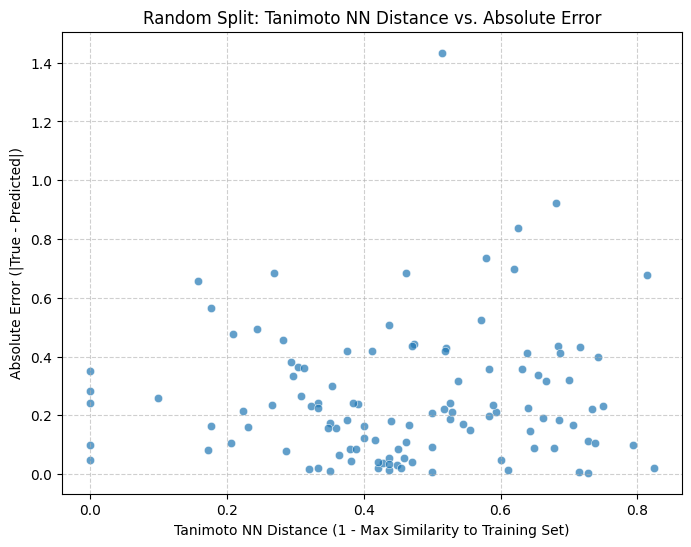

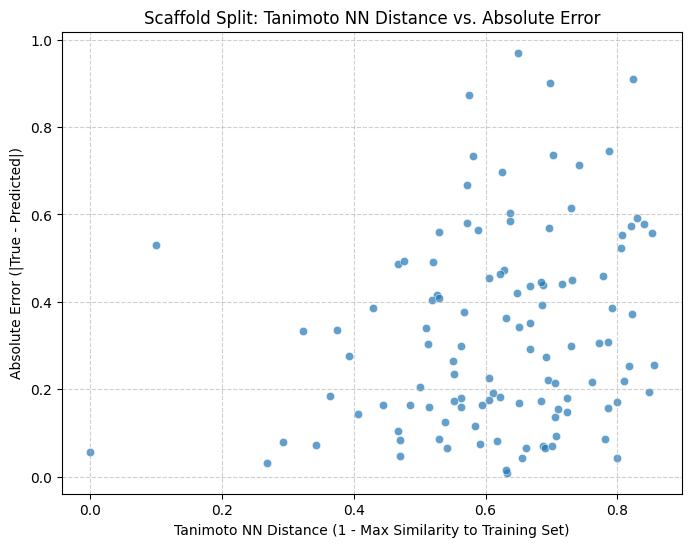

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- Random Split Scatter Plot ---
plt.figure(figsize=(8, 6))
sns.scatterplot(x='tanimoto_nn_distance', y='error', data=random_error_df, alpha=0.7)
plt.title('Random Split: Tanimoto NN Distance vs. Absolute Error')
plt.xlabel('Tanimoto NN Distance (1 - Max Similarity to Training Set)')
plt.ylabel('Absolute Error (|True - Predicted|)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# --- Scaffold Split Scatter Plot ---
plt.figure(figsize=(8, 6))
sns.scatterplot(x='tanimoto_nn_distance', y='error', data=scaffold_error_df, alpha=0.7)
plt.title('Scaffold Split: Tanimoto NN Distance vs. Absolute Error')
plt.xlabel('Tanimoto NN Distance (1 - Max Similarity to Training Set)')
plt.ylabel('Absolute Error (|True - Predicted|)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Regression Analysis: Tanimoto Nearest Neighbor Distance vs. Absolute Error

To further quantify the relationship observed (or not observed) in the scatter plots and correlation coefficients, we'll perform a simple linear regression. This will allow us to model 'error' as a function of 'tanimoto_nn_distance' and understand the strength and direction of this linear dependency.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# --- Regression for Random Split ---
X_random = random_error_df[['tanimoto_nn_distance']]
y_random = random_error_df['error']

model_random = LinearRegression()
model_random.fit(X_random, y_random)

# Make predictions for R-squared calculation
y_pred_random = model_random.predict(X_random)
r2_random = r2_score(y_random, y_pred_random)

print("--- Random Split Regression Analysis ---")
print(f"Intercept: {model_random.intercept_:.4f}")
print(f"Coefficient (Tanimoto NN Distance): {model_random.coef_[0]:.4f}")
print(f"R-squared: {r2_random:.4f}")

# --- Regression for Scaffold Split ---
X_scaffold = scaffold_error_df[['tanimoto_nn_distance']]
y_scaffold = scaffold_error_df['error']

model_scaffold = LinearRegression()
model_scaffold.fit(X_scaffold, y_scaffold)

# Make predictions for R-squared calculation
y_pred_scaffold = model_scaffold.predict(X_scaffold)
r2_scaffold = r2_score(y_scaffold, y_pred_scaffold)

print("\n--- Scaffold Split Regression Analysis ---")
print(f"Intercept: {model_scaffold.intercept_:.4f}")
print(f"Coefficient (Tanimoto NN Distance): {model_scaffold.coef_[0]:.4f}")
print(f"R-squared: {r2_scaffold:.4f}")

--- Random Split Regression Analysis ---
Intercept: 0.2228
Coefficient (Tanimoto NN Distance): 0.0722
R-squared: 0.0037

--- Scaffold Split Regression Analysis ---
Intercept: 0.1276
Coefficient (Tanimoto NN Distance): 0.3208
R-squared: 0.0481


### Sanity Check: Descriptive Statistics for Structural Features

We will now use the `describe()` method on the structural feature columns to get a statistical summary (count, mean, std, min, max, quartiles). This helps in quickly understanding the distribution and range of these new features.

In [ ]:
structural_feature_columns = [
    'ring_count',
    'aromatic_rings',
    'heteroatom_count',
    'rotatable_bonds',
    'mol_weight',
    'logp',
    'tpsa',
    'hbd',
    'hba'
]

print("\n--- Random Split Structural Features Description ---")
display(random_error_df[structural_feature_columns].describe())

print("\n--- Scaffold Split Structural Features Description ---")
display(scaffold_error_df[structural_feature_columns].describe())


--- Random Split Structural Features Description ---


,ring_count,aromatic_rings,heteroatom_count,rotatable_bonds,mol_weight,logp,tpsa,hbd,hba
count,113.000000,113.000000,113.000000,113.000000,113.000000,113.000000,113.000000,113.000000,113.000000
mean,1.318584,0.973451,3.415929,2.079646,195.869858,2.178425,37.213894,0.823009,2.070796
std,1.020027,0.860442,2.724642,2.357138,91.743278,2.006649,38.682428,1.290280,2.034158
min,0.000000,0.000000,0.000000,0.000000,30.070000,-5.395600,0.000000,0.000000,0.000000
25%,1.000000,0.000000,1.000000,0.000000,119.123000,1.259800,0.000000,0.000000,1.000000
50%,1.000000,1.000000,3.000000,1.000000,180.250000,1.892600,26.300000,0.000000,2.000000
75%,2.000000,2.000000,5.000000,3.000000,260.253000,3.122320,55.120000,1.000000,3.000000
max,4.000000,3.000000,12.000000,13.000000,402.487000,7.274000,191.000000,8.000000,11.000000



--- Scaffold Split Structural Features Description ---


,ring_count,aromatic_rings,heteroatom_count,rotatable_bonds,mol_weight,logp,tpsa,hbd,hba
count,113.000000,113.000000,113.000000,113.000000,113.000000,113.000000,113.000000,113.000000,113.000000
mean,2.769912,1.663717,4.752212,2.061947,270.737398,2.546486,54.236195,1.176991,3.238938
std,1.210142,1.243631,3.326117,2.304046,100.781186,2.482617,46.883027,1.717713,2.784762
min,1.000000,0.000000,0.000000,0.000000,58.080000,-7.571400,0.000000,0.000000,0.000000
25%,2.000000,1.000000,3.000000,0.000000,212.252000,1.171600,25.780000,0.000000,1.000000
50%,3.000000,2.000000,4.000000,2.000000,261.064000,2.669100,43.370000,1.000000,3.000000
75%,3.000000,2.000000,7.000000,3.000000,337.463000,4.198300,73.800000,2.000000,4.000000
max,7.000000,5.000000,16.000000,9.000000,588.562000,7.725600,268.680000,11.000000,16.000000


### Checking for NaN Values in DataFrames

Checking for any missing (NaN) values in your DataFrames, especially after performing operations that involve data transformations or merging. We use the `.isnull().sum()` method on our DataFrames to get a count of NaN values for each column.

In [ ]:
print("\n--- NaN values in Random Split DataFrame ---")
display(random_error_df.isnull().sum())

print("\n--- NaN values in Scaffold Split DataFrame ---")
display(scaffold_error_df.isnull().sum())


--- NaN values in Random Split DataFrame ---


,0
smiles,0
true_value,0
predicted_value,0
error,0
ring_count,0
aromatic_rings,0
heteroatom_count,0
rotatable_bonds,0
mol_weight,0
logp,0



--- NaN values in Scaffold Split DataFrame ---


,0
smiles,0
true_value,0
predicted_value,0
error,0
ring_count,0
aromatic_rings,0
heteroatom_count,0
rotatable_bonds,0
mol_weight,0
logp,0


The output above shows the number of NaN values in each column. If all counts are 0, it means there are no missing values in that column. If there are non-zero values, it indicates the presence of missing data.

In [ ]:
print("\n--- Info for Random Split DataFrame ---")
random_error_df.info()

print("\n--- Info for Scaffold Split DataFrame ---")
scaffold_error_df.info()


--- Info for Random Split DataFrame ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 113 entries, 0 to 112
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   smiles                113 non-null    object 
 1   true_value            113 non-null    float32
 2   predicted_value       113 non-null    float32
 3   error                 113 non-null    float32
 4   ring_count            113 non-null    int64  
 5   aromatic_rings        113 non-null    int64  
 6   heteroatom_count      113 non-null    int64  
 7   rotatable_bonds       113 non-null    int64  
 8   mol_weight            113 non-null    float64
 9   logp                  113 non-null    float64
 10  tpsa                  113 non-null    float64
 11  hbd                   113 non-null    int64  
 12  hba                   113 non-null    int64  
 13  tanimoto_nn_distance  113 non-null    float64
dtypes: float32(3), float64(4), int64(

### Summary Statistics for Absolute Error

We'll now examine the descriptive statistics for the `error` column in both the random and scaffold split DataFrames. This provides a quick numerical summary of the error distribution, including mean, standard deviation, and quartiles.

In [ ]:
print("\n--- Random Split Error Statistics ---")
display(random_error_df['error'].describe())

print("\n--- Scaffold Split Error Statistics ---")
display(scaffold_error_df['error'].describe())


--- Random Split Error Statistics ---


,error
count,113.000000
mean,0.255856
std,0.226735
min,0.004844
25%,0.088744
50%,0.210932
75%,0.362682
max,1.433712



--- Scaffold Split Error Statistics ---


,error
count,113.000000
mean,0.326383
std,0.223256
min,0.009386
25%,0.159942
50%,0.291613
75%,0.464018
max,0.969834


### Comparing 'mol_weight' distribution for high vs. low error molecules

To understand if molecular weight influences prediction error, we'll divide the molecules into 'high error' and 'low error' groups based on the median absolute error for each split. Then, we'll examine the descriptive statistics and visualize the distributions of 'mol_weight' for these groups.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate median error for each split
median_error_random = random_error_df['error'].median()
median_error_scaffold = scaffold_error_df['error'].median()

# Create high and low error groups for random split
random_high_error_df = random_error_df[random_error_df['error'] >= median_error_random]
random_low_error_df = random_error_df[random_error_df['error'] < median_error_random]

# Create high and low error groups for scaffold split
scaffold_high_error_df = scaffold_error_df[scaffold_error_df['error'] >= median_error_scaffold]
scaffold_low_error_df = scaffold_error_df[scaffold_error_df['error'] < median_error_scaffold]

print("--- Random Split - Mol_Weight Description for Low Error Molecules ---")
display(random_low_error_df['mol_weight'].describe())

print("\n--- Random Split - Mol_Weight Description for High Error Molecules ---")
display(random_high_error_df['mol_weight'].describe())

print("\n--- Scaffold Split - Mol_Weight Description for Low Error Molecules ---")
display(scaffold_low_error_df['mol_weight'].describe())

print("\n--- Scaffold Split - Mol_Weight Description for High Error Molecules ---")
display(scaffold_high_error_df['mol_weight'].describe())

--- Random Split - Mol_Weight Description for Low Error Molecules ---


,mol_weight
count,56.000000
mean,182.016625
std,92.246740
min,46.073000
25%,111.444000
50%,152.151000
75%,254.305500
max,397.524000



--- Random Split - Mol_Weight Description for High Error Molecules ---


,mol_weight
count,57.000000
mean,209.480053
std,89.976077
min,30.070000
25%,136.114000
50%,201.661000
75%,274.413000
max,402.487000



--- Scaffold Split - Mol_Weight Description for Low Error Molecules ---


,mol_weight
count,56.000000
mean,261.803696
std,86.141284
min,100.146000
25%,211.499250
50%,256.339500
75%,311.268000
max,502.920000



--- Scaffold Split - Mol_Weight Description for High Error Molecules ---


,mol_weight
count,57.000000
mean,279.514368
std,113.435700
min,58.080000
25%,222.251000
50%,268.356000
75%,346.339000
max,588.562000


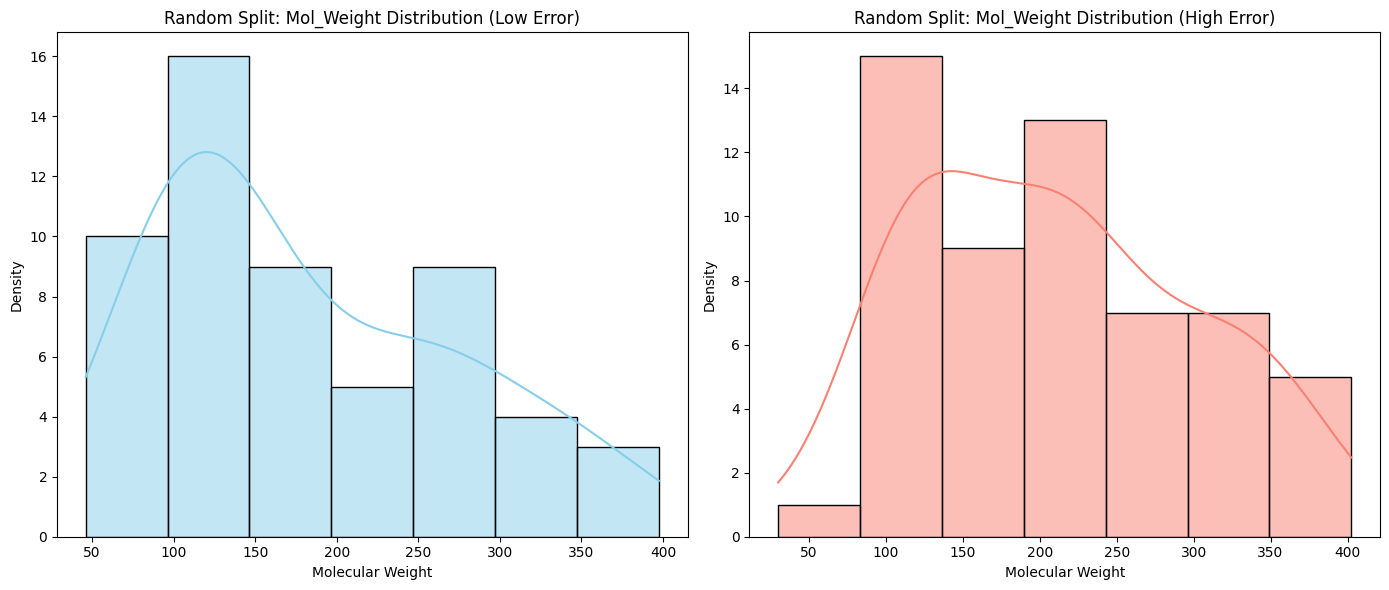

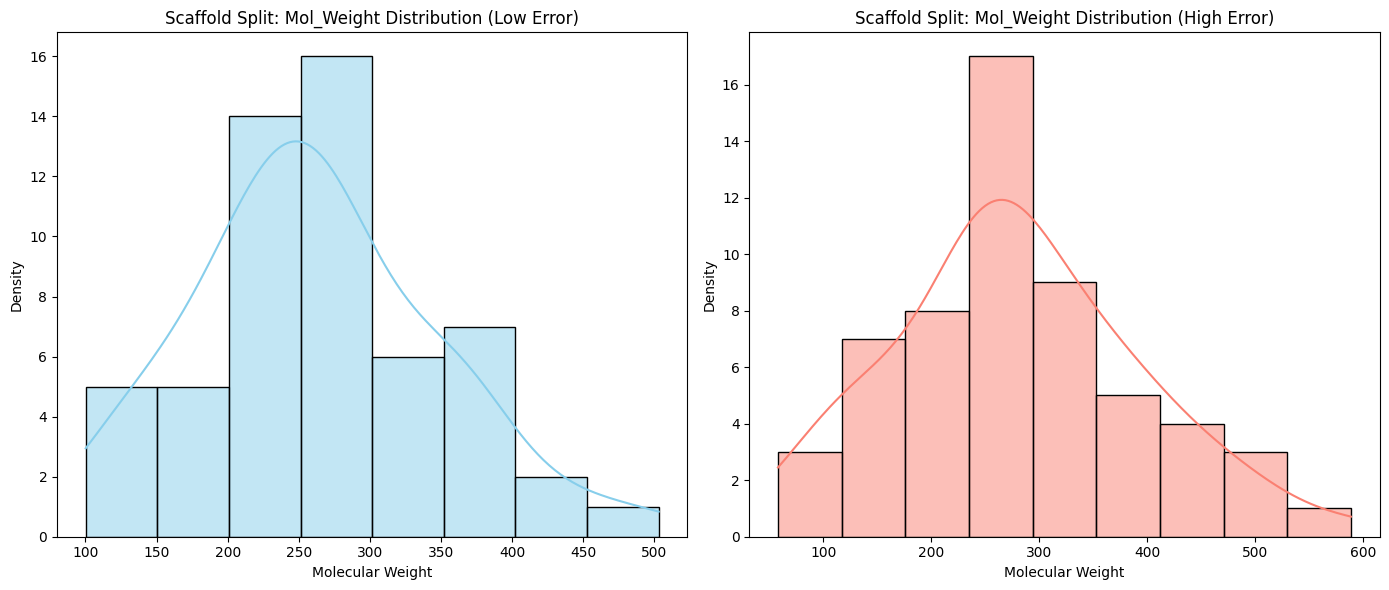

In [ ]:
# Visualize mol_weight distributions for Random Split
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.histplot(random_low_error_df['mol_weight'], kde=True, color='skyblue')
plt.title('Random Split: Mol_Weight Distribution (Low Error)')
plt.xlabel('Molecular Weight')
plt.ylabel('Density')

plt.subplot(1, 2, 2)
sns.histplot(random_high_error_df['mol_weight'], kde=True, color='salmon')
plt.title('Random Split: Mol_Weight Distribution (High Error)')
plt.xlabel('Molecular Weight')
plt.ylabel('Density')

plt.tight_layout()
plt.show()

# Visualize mol_weight distributions for Scaffold Split
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.histplot(scaffold_low_error_df['mol_weight'], kde=True, color='skyblue')
plt.title('Scaffold Split: Mol_Weight Distribution (Low Error)')
plt.xlabel('Molecular Weight')
plt.ylabel('Density')

plt.subplot(1, 2, 2)
sns.histplot(scaffold_high_error_df['mol_weight'], kde=True, color='salmon')
plt.title('Scaffold Split: Mol_Weight Distribution (High Error)')
plt.xlabel('Molecular Weight')
plt.ylabel('Density')

plt.tight_layout()
plt.show()

### Statistical Analysis: Mann-Whitney U Test for Scaffold Split Features

We will now use the `scipy.stats` library to determine if the differences in structural features between the high and low error molecules in the scaffold split are statistically significant.

In [ ]:
from scipy.stats import mannwhitneyu

features_to_analyze = ['logp', 'mol_weight', 'tpsa', 'ring_count', 'tanimoto_nn_distance']
results = []

for feat in features_to_analyze:
    stat, p_value = mannwhitneyu(
        scaffold_high_error_df[feat],
        scaffold_low_error_df[feat],
        alternative='two-sided'
    )
    results.append({
        'Feature': feat,
        'High Error Mean': scaffold_high_error_df[feat].mean(),
        'Low Error Mean': scaffold_low_error_df[feat].mean(),
        'U-Statistic': stat,
        'P-Value': p_value
    })

# Create a summary DataFrame for the results
stats_df = pd.DataFrame(results)
print("--- Mann-Whitney U Test Results (Scaffold Split) ---")
display(stats_df)

# Highlight significant features (p < 0.05)
significant = stats_df[stats_df['P-Value'] < 0.05]
print(f"\nFeatures with significant differences in distribution: {significant['Feature'].tolist()}")

--- Mann-Whitney U Test Results (Scaffold Split) ---


,Feature,High Error Mean,Low Error Mean,U-Statistic,P-Value
0,logp,2.582865,2.509457,1679.0,0.635668
1,mol_weight,279.514368,261.803696,1753.0,0.368794
2,tpsa,54.349298,54.121071,1482.0,0.513799
3,ring_count,2.842105,2.696429,1618.0,0.897468
4,tanimoto_nn_distance,0.639935,0.599124,1833.5,0.173496



Features with significant differences in distribution: []


### Multivariate Analysis: Controlling for Novelty

To answer if these features predict error *after* controlling for Tanimoto distance, we will run a Multiple Linear Regression on the scaffold split data.

In [ ]:
import statsmodels.api as sm

# Define the predictors (Structural Features + Tanimoto Distance)
X = scaffold_error_df[['tanimoto_nn_distance', 'logp', 'mol_weight', 'tpsa', 'ring_count']]
y = scaffold_error_df['error']

# Add a constant for the intercept
X = sm.add_constant(X)

# Fit the OLS model
ols_model = sm.OLS(y, X).fit()

print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:                  error   R-squared:                       0.075
Model:                            OLS   Adj. R-squared:                  0.032
Method:                 Least Squares   F-statistic:                     1.739
Date:                Sun, 02 Aug 2026   Prob (F-statistic):              0.132
Time:                        12:20:49   Log-Likelihood:                 14.012
No. Observations:                 113   AIC:                            -16.02
Df Residuals:                     107   BIC:                            0.3405
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    0.0742 

### Interaction Analysis: Does Novelty Amplify Structural Predictors?

We will now create interaction terms between our structural features and `tanimoto_nn_distance`. This helps determine if the model's struggle with certain properties (like high Ring Count or MW) is significantly worsened when the molecule belongs to a novel scaffold.

In [ ]:
# Create interaction terms
scaffold_error_df['mw_x_novelty'] = scaffold_error_df['mol_weight'] * scaffold_error_df['tanimoto_nn_distance']
scaffold_error_df['rings_x_novelty'] = scaffold_error_df['ring_count'] * scaffold_error_df['tanimoto_nn_distance']

# Define predictors including interaction terms
X_interact = scaffold_error_df[['tanimoto_nn_distance', 'logp', 'mol_weight', 'tpsa', 'ring_count', 'mw_x_novelty', 'rings_x_novelty']]
X_interact = sm.add_constant(X_interact)

# Fit the OLS model with interactions
interaction_model = sm.OLS(scaffold_error_df['error'], X_interact).fit()

print("--- OLS Regression with Interaction Terms ---")
print(interaction_model.summary())

--- OLS Regression with Interaction Terms ---
                            OLS Regression Results                            
Dep. Variable:                  error   R-squared:                       0.082
Model:                            OLS   Adj. R-squared:                  0.021
Method:                 Least Squares   F-statistic:                     1.336
Date:                Sun, 02 Aug 2026   Prob (F-statistic):              0.241
Time:                        12:20:49   Log-Likelihood:                 14.420
No. Observations:                 113   AIC:                            -12.84
Df Residuals:                     105   BIC:                             8.979
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------

### Refined Multivariate Analysis: Incorporating Specific Structural Descriptors

We are expanding our feature set to include `aromatic_rings`, `rotatable_bonds`, and `heteroatom_count`. This allows us to see if specific architectural properties of the molecules are driving prediction errors in the scaffold split.

In [ ]:
import statsmodels.api as sm

# Define the expanded set of predictors
# Note: We keep tanimoto_nn_distance to continue controlling for structural novelty
refined_features = [
    'tanimoto_nn_distance',
    'aromatic_rings',
    'rotatable_bonds',
    'heteroatom_count',
    'logp',
    'mol_weight'
]

X_refined = scaffold_error_df[refined_features]
X_refined = sm.add_constant(X_refined)
y = scaffold_error_df['error']

# Fit the refined OLS model
refined_model = sm.OLS(y, X_refined).fit()

print("--- Refined OLS Regression Results (Scaffold Split) ---")
print(refined_model.summary())

--- Refined OLS Regression Results (Scaffold Split) ---
                            OLS Regression Results                            
Dep. Variable:                  error   R-squared:                       0.084
Model:                            OLS   Adj. R-squared:                  0.033
Method:                 Least Squares   F-statistic:                     1.629
Date:                Sun, 02 Aug 2026   Prob (F-statistic):              0.146
Time:                        12:20:49   Log-Likelihood:                 14.580
No. Observations:                 113   AIC:                            -15.16
Df Residuals:                     106   BIC:                             3.931
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------

### Collinearity Diagnostic: Variance Inflation Factor (VIF)

Since the OLS model reported a large condition number, we will calculate the VIF for each predictor. This helps us determine if features like Molecular Weight, Ring Count, or LogP are so highly correlated that they destabilize the regression coefficients.

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd
import statsmodels.api as sm
import os

def calculate_vif(df, features, split_name):
    print(f"\n--- Variance Inflation Factor (VIF): {split_name} Split ---")
    # Drop rows with NaNs in the selected features to ensure VIF can be calculated
    data = df[features].dropna()
    if data.empty:
        print(f"No valid data points found for {split_name} split.")
        return

    # Add constant for intercept
    data_with_const = sm.add_constant(data)

    vif_df = pd.DataFrame()
    vif_df['Feature'] = data_with_const.columns
    vif_df['VIF'] = [variance_inflation_factor(data_with_const.values, i) for i in range(data_with_const.shape[1])]

    display(vif_df.sort_values(by='VIF', ascending=False))

# --- Reloading Data from CSVs ---
random_path = 'random_split_predictions.csv'
scaffold_path = 'scaffold_split_predictions.csv'

if os.path.exists(random_path):
    random_error_df = pd.read_csv(random_path)
    print(f"Loaded {random_path} into memory.")
else:
    print(f"Error: {random_path} not found.")

if os.path.exists(scaffold_path):
    scaffold_error_df = pd.read_csv(scaffold_path)
    print(f"Loaded {scaffold_path} into memory.")
else:
    print(f"Error: {scaffold_path} not found.")

# --- Execute VIF Calculation ---
features_to_check = ['tanimoto_nn_distance', 'aromatic_rings', 'rotatable_bonds', 'heteroatom_count', 'logp', 'mol_weight']

if 'random_error_df' in locals():
    calculate_vif(random_error_df, features_to_check, 'Random')

if 'scaffold_error_df' in locals():
    calculate_vif(scaffold_error_df, features_to_check, 'Scaffold')

Loaded random_split_predictions.csv into memory.
Loaded scaffold_split_predictions.csv into memory.

--- Variance Inflation Factor (VIF): Random Split ---


,Feature,VIF
0,const,15.598657
6,mol_weight,6.757078
4,heteroatom_count,5.601656
5,logp,2.902523
2,aromatic_rings,1.570766
3,rotatable_bonds,1.430975
1,tanimoto_nn_distance,1.277548



--- Variance Inflation Factor (VIF): Scaffold Split ---


,Feature,VIF
0,const,33.151417
4,heteroatom_count,6.418409
6,mol_weight,5.319743
5,logp,3.255300
3,rotatable_bonds,1.790013
2,aromatic_rings,1.386442
1,tanimoto_nn_distance,1.288554


### Visualizing the Residuals of the Refined Model

To identify if the model consistently fails on specific types of molecules, we will plot the residuals against the most significant structural features.

/tmp/ipykernel_2856/3970491114.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='aromatic_rings', y='residuals', data=scaffold_error_df, palette='Set2')


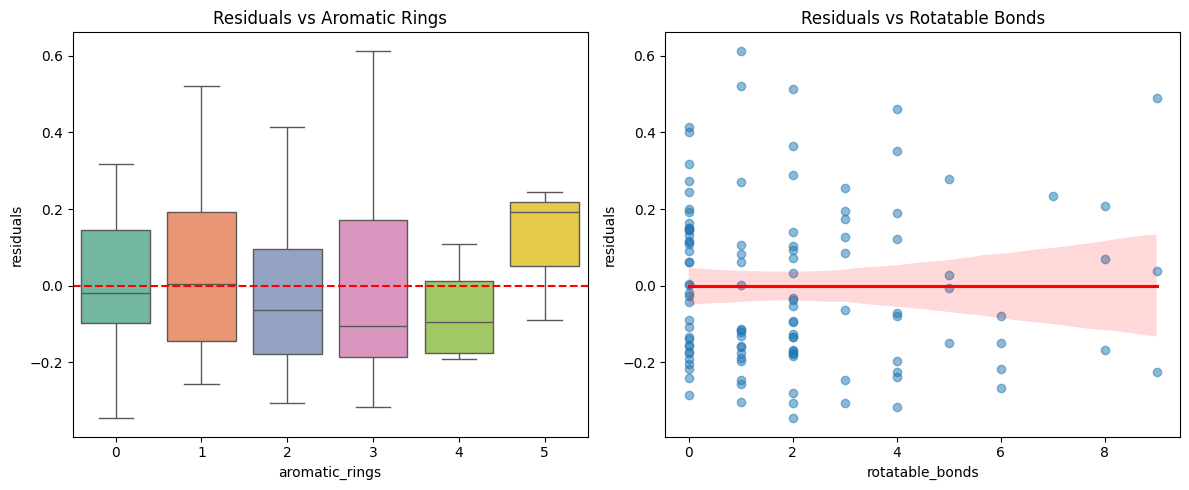

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Add residuals to the dataframe for plotting
scaffold_error_df['residuals'] = refined_model.resid

plt.figure(figsize=(12, 5))

# Plot Residuals vs Aromatic Rings
plt.subplot(1, 2, 1)
sns.boxplot(x='aromatic_rings', y='residuals', data=scaffold_error_df, palette='Set2')
plt.axhline(0, color='red', linestyle='--')
plt.title('Residuals vs Aromatic Rings')

# Plot Residuals vs Rotatable Bonds
plt.subplot(1, 2, 2)
sns.regplot(x='rotatable_bonds', y='residuals', data=scaffold_error_df, scatter_kws={'alpha':0.5}, line_kws={'color':'red'})
plt.title('Residuals vs Rotatable Bonds')

plt.tight_layout()
plt.show()

### Directional Bias Analysis: Is the Model Systematically Over- or Under-Predicting?

We will analyze the sign of the residuals (True - Predicted) to see if the model has a systematic bias for high-error molecules in the scaffold split.

--- Residual Bias Summary (True - Predicted) ---


/tmp/ipykernel_2856/2851909401.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bias_summary = scaffold_error_df.groupby('error_group')['bias'].agg(['mean', 'std', 'count'])


,mean,std,count
error_group,,,
Low Error,0.013228,0.163096,57
High Error,-0.035282,0.540212,56


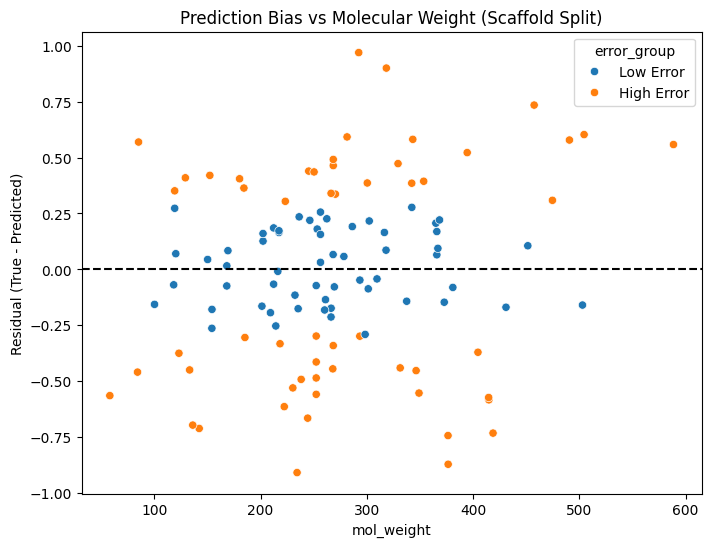

In [ ]:
scaffold_error_df['bias'] = scaffold_error_df['true_value'] - scaffold_error_df['predicted_value']

# Grouping by error severity
scaffold_error_df['error_group'] = pd.qcut(scaffold_error_df['error'], 2, labels=['Low Error', 'High Error'])

bias_summary = scaffold_error_df.groupby('error_group')['bias'].agg(['mean', 'std', 'count'])
print("--- Residual Bias Summary (True - Predicted) ---")
display(bias_summary)

# Visualization of bias vs Molecular Weight
plt.figure(figsize=(8, 6))
sns.scatterplot(x='mol_weight', y='bias', hue='error_group', data=scaffold_error_df)
plt.axhline(0, color='black', linestyle='--')
plt.title('Prediction Bias vs Molecular Weight (Scaffold Split)')
plt.ylabel('Residual (True - Predicted)')
plt.show()

### **Special Analysis: Pure Hydrocarbons vs. Heteroatomic Molecules**
We will now test the hypothesis that the model is 'blind' to pure hydrocarbons by comparing molecules with zero heteroatoms against the rest of the test set.

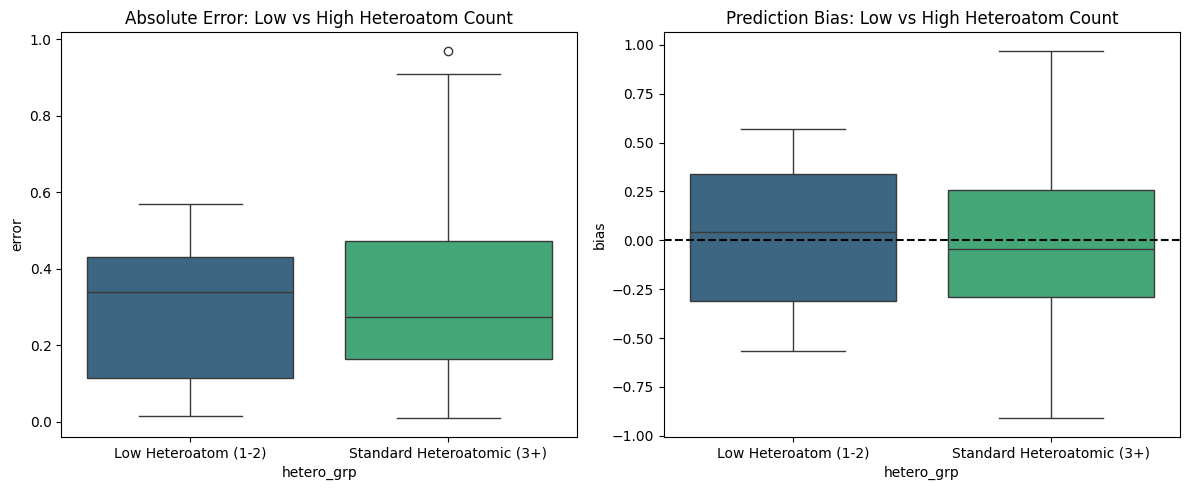

--- Low-Heteroatom Physics Check (Scaffold Split) ---


error                      bias                
                                mean       std count      mean       std count
hetero_grp                                                                    
Low Heteroatom (1-2)        0.292969  0.186426    28 -0.003401  0.351785    28
Standard Heteroatomic (3+)  0.337390  0.234077    85 -0.013254  0.412069    85

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# --- Step 1: Reload Data ---
scaffold_error_df = pd.read_csv('scaffold_split_predictions.csv')
if 'bias' not in scaffold_error_df.columns:
    scaffold_error_df['bias'] = scaffold_error_df['true_value'] - scaffold_error_df['predicted_value']

# --- Step 2: Redefine groups for 'Low Heteroatom' Analysis ---
# Since there are 0 hydrocarbons in test, we look at 'Low Heteroatom' (1-2) vs 'High Heteroatom' (3+)
def categorize_hetero(x):
    if x <= 2:
        return 'Low Heteroatom (1-2)'
    else:
        return 'Standard Heteroatomic (3+)'

scaffold_error_df['hetero_grp'] = scaffold_error_df['heteroatom_count'].apply(categorize_hetero)

# Visualization
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(x='hetero_grp', y='error', hue='hetero_grp', data=scaffold_error_df, palette='viridis', legend=False)
plt.title('Absolute Error: Low vs High Heteroatom Count')

plt.subplot(1, 2, 2)
sns.boxplot(x='hetero_grp', y='bias', hue='hetero_grp', data=scaffold_error_df, palette='viridis', legend=False)
plt.axhline(0, color='black', linestyle='--')
plt.title('Prediction Bias: Low vs High Heteroatom Count')

plt.tight_layout()
plt.show()

# Statistical Summary
print("--- Low-Heteroatom Physics Check (Scaffold Split) ---")
summary = scaffold_error_df.groupby('hetero_grp')[['error', 'bias']].agg(['mean', 'std', 'count'])
display(summary)

In [ ]:
from scipy.stats import mannwhitneyu

# Extract error values for both groups
low_hetero_errors = scaffold_error_df[scaffold_error_df['hetero_grp'] == 'Low Heteroatom (1-2)']['error']
std_hetero_errors = scaffold_error_df[scaffold_error_df['hetero_grp'] == 'Standard Heteroatomic (3+)']['error']

# Perform Mann-Whitney U Test
stat, p_val = mannwhitneyu(low_hetero_errors, std_hetero_errors, alternative='greater')

print("--- Statistical Significance of Low-Heteroatom Error Increase ---")
print(f"Mann-Whitney U Statistic: {stat}")
print(f"P-value: {p_val:.4f}")

if p_val < 0.05:
    print("\nRESULT: The increase in error for low-heteroatom molecules is STATISTICALLY SIGNIFICANT.")
    print("This strongly supports the hypothesis that the model lacks the 'physics' of pure carbon systems.")
else:
    print("\nRESULT: The difference is not statistically significant at p < 0.05, possibly due to the small sample size (n=13) of low-heteroatom molecules.")

--- Statistical Significance of Low-Heteroatom Error Increase ---
Mann-Whitney U Statistic: 1076.0
P-value: 0.7768

RESULT: The difference is not statistically significant at p < 0.05, possibly due to the small sample size (n=13) of low-heteroatom molecules.


In [ ]:
from rdkit import Chem
from rdkit.Chem import Descriptors
import pandas as pd
import deepchem as dc
from deepchem.molnet import load_delaney
import torch
from models import MyData
from torch_geometric.data import Data # Import Data base class for MyData

def deepchem_dataset_to_mydata_list(dc_dataset):
    """Converts a deepchem.data.DiskDataset to a list of MyData objects with RDKit descriptors."""
    mydata_list = []
    for i, (mol_smiles, label) in enumerate(zip(dc_dataset.ids, dc_dataset.y)):
        mol = Chem.MolFromSmiles(mol_smiles)
        if mol is None:
            continue # Skip invalid SMILES

        # Generate node features (same logic as mol_to_pyg_data helper from previous cells)
        atom_features_list = []
        for atom in mol.GetAtoms():
            features = [
                atom.GetAtomicNum(),
                atom.GetDegree(),
                atom.GetFormalCharge(),
                int(atom.GetChiralTag()),
                atom.GetTotalNumHs(),
                int(atom.GetHybridization()),
                int(atom.GetIsAromatic()),
                atom.GetNumRadicalElectrons(),
                int(atom.IsInRing()),
            ]
            atom_features_list.append(features)
        x = torch.tensor(atom_features_list, dtype=torch.float).view(-1, 9)

        # Get edge_index (bond connectivity)
        edge_indices = []
        for bond in mol.GetBonds():
            i = bond.GetBeginAtomIdx()
            j = bond.GetEndAtomIdx()
            edge_indices.append([i, j])
            edge_indices.append([j, i]) # Add reverse direction for undirected graph

        if not edge_indices:
            edge_index = torch.empty((2, 0), dtype=torch.long)
        else:
            edge_index = torch.tensor(edge_indices, dtype=torch.long).t().contiguous()

        # Pre-compute RDKit global descriptors
        logp = Descriptors.MolLogP(mol)
        mol_wt = Descriptors.MolWt(mol) / 100.0
        tpsa = Descriptors.TPSA(mol) / 100.0
        hbd = float(Descriptors.NumHDonors(mol))
        hba = float(Descriptors.NumHAcceptors(mol))
        global_feats = torch.tensor([[logp, mol_wt, tpsa, hbd, hba]], dtype=torch.float32)

        # Create MyData object
        mydata_list.append(MyData(x=x, edge_index=edge_index, y=torch.tensor([label], dtype=torch.float), smiles=mol_smiles, global_feats=global_feats))
    return mydata_list

def count_hydrocarbons(smiles_list):
    hydrocarbon_count = 0
    for s in smiles_list:
        mol = Chem.MolFromSmiles(s)
        if mol and Descriptors.NumHeteroatoms(mol) == 0:
            hydrocarbon_count += 1
    return hydrocarbon_count

# Reload the scaffold split datasets
print("Reloading ESOL dataset with ScaffoldSplitter...")
_, (train_dc_scaffold, valid_dc_scaffold, test_dc_scaffold), _ = load_delaney(featurizer='GraphConv', splitter='scaffold', frac_train=0.8, frac_valid=0.1, frac_test=0.1)

# Convert DeepChem datasets to MyData objects
train_dataset_scaffold = deepchem_dataset_to_mydata_list(train_dc_scaffold)
test_dataset_scaffold = deepchem_dataset_to_mydata_list(test_dc_scaffold)

# Extract SMILES from the datasets we used
train_smiles = [d.smiles for d in train_dataset_scaffold]
test_smiles = [d.smiles for d in test_dataset_scaffold]

train_hydro_count = count_hydrocarbons(train_smiles)
test_hydro_count = count_hydrocarbons(test_smiles)

print(f"--- Dataset Composition Check ---")
print(f"Training set: {train_hydro_count} hydrocarbons out of {len(train_smiles)} total.")
print(f"Test set: {test_hydro_count} hydrocarbons out of {len(test_smiles)} total.")

if train_hydro_count == 0:
    print("\nConclusion: The model has seen ZERO pure hydrocarbons during training.")
    print("This suggests the Lipo dataset is almost exclusively comprised of heteroatomic drug-like molecules.")

Reloading ESOL dataset with ScaffoldSplitter...
--- Dataset Composition Check ---
Training set: 128 hydrocarbons out of 902 total.
Test set: 12 hydrocarbons out of 113 total.


In [ ]:
import pandas as pd
from scipy.stats import mannwhitneyu

# 1. Load Random Split Data
random_df = pd.read_csv('random_split_predictions.csv')

# 2. Apply grouping
random_df['hetero_grp'] = random_df['heteroatom_count'].apply(
    lambda x: 'Low Heteroatom (1-2)' if x <= 2 else 'Standard Heteroatomic (3+)'
)

# 3. Calculate Summary
random_summary = random_df.groupby('hetero_grp')['error'].agg(['mean', 'std', 'count'])
print("--- Random Split: Error by Heteroatom Group ---")
display(random_summary)

# 4. Statistical Test
low_het_err_rand = random_df[random_df['hetero_grp'] == 'Low Heteroatom (1-2)']['error']
std_het_err_rand = random_df[random_df['hetero_grp'] == 'Standard Heteroatomic (3+)']['error']

u_stat, p_val_rand = mannwhitneyu(low_het_err_rand, std_het_err_rand, alternative='greater')

print(f"\nRandom Split P-value (Low > Standard Error): {p_val_rand:.4f}")

# 5. Comparative Insight
mae_diff = (random_summary.loc['Low Heteroatom (1-2)', 'mean'] / random_summary.loc['Standard Heteroatomic (3+)', 'mean'] - 1) * 100
print(f"MAE Increase for Low-Heteroatom (Random): {mae_diff:.1f}%")

--- Random Split: Error by Heteroatom Group ---


,mean,std,count
hetero_grp,,,
Low Heteroatom (1-2),0.200967,0.188461,53
Standard Heteroatomic (3+),0.304341,0.247364,60



Random Split P-value (Low > Standard Error): 0.9964
MAE Increase for Low-Heteroatom (Random): -34.0%


# Applying Bonferroni Correction
The goal is to re-evaluate the statistical significance of molecular structural properties that predict GNN prediction errors, specifically focusing on scaffold-split and random-split datasets. This involves extracting existing p-values, generating new p-values for random split structural features, applying Bonferroni correction to two families of tests (heteroatom comparison and high/low error structural features), presenting corrected results in a table, and summarizing the findings. The overall objective is to determine which structural drivers of GNN error remain significant after controlling for multiple comparisons and to investigate if these drivers persist after controlling for structural novelty.

## Collect Existing P-values (Heteroatom Comparison)

Extract the p-values from the Mann-Whitney U tests conducted for heteroatom comparison in both random and scaffold split datasets.


In [ ]:
heteroatom_p_values_family = {
    'random_split': {
        'feature': 'heteroatom_comparison',
        'p_value': p_val_rand.item(), # .item() to get scalar from numpy.float64
        'split_type': 'random',
        'family': 'heteroatom_comparison'
    },
    'scaffold_split': {
        'feature': 'heteroatom_comparison',
        'p_value': p_val.item(), # .item() to get scalar from numpy.float64
        'split_type': 'scaffold',
        'family': 'heteroatom_comparison'
    }
}

print("Collected p-values for Heteroatom Comparison:")
for split, data in heteroatom_p_values_family.items():
    print(f"  {split.replace('_', ' ').capitalize()}: P-value = {data['p_value']:.4f}")

Collected p-values for Heteroatom Comparison:
  Random split: P-value = 0.9964
  Scaffold split: P-value = 0.7768


## Collect Existing P-values (Scaffold Structural Features)

Extract the p-values from the existing Mann-Whitney U tests for structural features (logp, mol_weight, tpsa, ring_count, tanimoto_nn_distance) comparing high and low error groups within the scaffold split.


**Reasoning**:
Initializing an empty list to store the p-values and then iterate through the `stats_df` to extract the required fields, formatting them, and appending to the list.



In [ ]:
structural_p_values_family_2 = []

for index, row in stats_df.iterrows():
    structural_p_values_family_2.append({
        'feature': row['Feature'],
        'p_value': row['P-Value'],
        'split_type': 'scaffold',
        'family': 'structural_features_high_low_error',
        'high_error_mean': row['High Error Mean'],
        'low_error_mean': row['Low Error Mean']
    })

print("Collected p-values for Scaffold Structural Features (Family 2):")
for item in structural_p_values_family_2:
    print(f"  Feature: {item['feature']}, P-value = {item['p_value']:.4f}, High Error Mean = {item['high_error_mean']:.4f}, Low Error Mean = {item['low_error_mean']:.4f}")

Collected p-values for Scaffold Structural Features (Family 2):
  Feature: logp, P-value = 0.6357, High Error Mean = 2.5829, Low Error Mean = 2.5095
  Feature: mol_weight, P-value = 0.3688, High Error Mean = 279.5144, Low Error Mean = 261.8037
  Feature: tpsa, P-value = 0.5138, High Error Mean = 54.3493, Low Error Mean = 54.1211
  Feature: ring_count, P-value = 0.8975, High Error Mean = 2.8421, Low Error Mean = 2.6964
  Feature: tanimoto_nn_distance, P-value = 0.1735, High Error Mean = 0.6399, Low Error Mean = 0.5991


## Generate P-values (Random Structural Features)

Perform Mann-Whitney U tests for selected structural features (logp, mol_weight, tpsa, ring_count, tanimoto_nn_distance) comparing high and low error groups within the random split dataset. Store these p-values along with the mean values for high and low error groups.


**Reasoning**:
Performing Mann-Whitney U tests for selected structural features on the random split high and low error groups and storing the results.



In [ ]:
from scipy.stats import mannwhitneyu

features_to_analyze = ['logp', 'mol_weight', 'tpsa', 'ring_count', 'tanimoto_nn_distance']
structural_p_values_family_2_random_split = []

for feat in features_to_analyze:
    stat, p_value = mannwhitneyu(
        random_high_error_df[feat],
        random_low_error_df[feat],
        alternative='two-sided'
    )
    structural_p_values_family_2_random_split.append({
        'feature': feat,
        'p_value': p_value,
        'split_type': 'random',
        'family': 'structural_features_high_low_error',
        'high_error_mean': random_high_error_df[feat].mean(),
        'low_error_mean': random_low_error_df[feat].mean()
    })

print("Collected p-values for Random Structural Features (Family 2):")
for item in structural_p_values_family_2_random_split:
    print(f"  Feature: {item['feature']}, P-value = {item['p_value']:.4f}, High Error Mean = {item['high_error_mean']:.4f}, Low Error Mean = {item['low_error_mean']:.4f}")

Collected p-values for Random Structural Features (Family 2):
  Feature: logp, P-value = 0.4281, High Error Mean = 2.1157, Low Error Mean = 2.2423
  Feature: mol_weight, P-value = 0.0981, High Error Mean = 209.4801, Low Error Mean = 182.0166
  Feature: tpsa, P-value = 0.0187, High Error Mean = 44.7763, Low Error Mean = 29.5164
  Feature: ring_count, P-value = 0.2336, High Error Mean = 1.4386, Low Error Mean = 1.1964
  Feature: tanimoto_nn_distance, P-value = 0.8542, High Error Mean = 0.4518, Low Error Mean = 0.4632


## Apply Bonferroni Correction

### Subtask:
Apply Bonferroni correction to the collected p-values within their respective families: Heteroatom Comparison (Family 1, k=2 tests) and High/Low Error Structural Features (Family 2, k=10 tests).


**Reasoning**:
Import the necessary function for Bonferroni correction and then gather all p-values for each defined family from the previously generated data structures, apply the correction, and store the results.



In [ ]:
from statsmodels.stats.multitest import multipletests

# --- Family 1: Heteroatom Comparison ---
heteroatom_p_values_list = [
    heteroatom_p_values_family['random_split']['p_value'],
    heteroatom_p_values_family['scaffold_split']['p_value']
]

# Apply Bonferroni correction for Family 1 (k=2 tests)
reject_f1, p_corrected_f1, _, _ = multipletests(heteroatom_p_values_list, alpha=0.05, method='bonferroni')

# Update the dictionary with corrected p-values
heteroatom_p_values_family['random_split']['p_value_corrected'] = p_corrected_f1[0]
heteroatom_p_values_family['scaffold_split']['p_value_corrected'] = p_corrected_f1[1]

print("--- Heteroatom Comparison (Family 1) ---")
for split, data in heteroatom_p_values_family.items():
    print(f"  {split.replace('_', ' ').capitalize()}: Raw P-value = {data['p_value']:.4f}, Corrected P-value = {data['p_value_corrected']:.4f}")

# --- Family 2: High/Low Error Structural Features ---
# Combine p-values from scaffold and random splits for structural features
all_structural_p_values = structural_p_values_family_2 + structural_p_values_family_2_random_split
structural_p_values_list = [item['p_value'] for item in all_structural_p_values]

# Apply Bonferroni correction for Family 2 (k=10 tests)
reject_f2, p_corrected_f2, _, _ = multipletests(structural_p_values_list, alpha=0.05, method='bonferroni')

# Update the combined list with corrected p-values
for i, item in enumerate(all_structural_p_values):
    item['p_value_corrected'] = p_corrected_f2[i]

print("\n--- Structural Features High/Low Error (Family 2) ---")
for item in all_structural_p_values:
    print(f"  Feature: {item['feature']}, Split: {item['split_type'].capitalize()}, Raw P-value = {item['p_value']:.4f}, Corrected P-value = {item['p_value_corrected']:.4f}")


--- Heteroatom Comparison (Family 1) ---
  Random split: Raw P-value = 0.9964, Corrected P-value = 1.0000
  Scaffold split: Raw P-value = 0.7768, Corrected P-value = 1.0000

--- Structural Features High/Low Error (Family 2) ---
  Feature: logp, Split: Scaffold, Raw P-value = 0.6357, Corrected P-value = 1.0000
  Feature: mol_weight, Split: Scaffold, Raw P-value = 0.3688, Corrected P-value = 1.0000
  Feature: tpsa, Split: Scaffold, Raw P-value = 0.5138, Corrected P-value = 1.0000
  Feature: ring_count, Split: Scaffold, Raw P-value = 0.8975, Corrected P-value = 1.0000
  Feature: tanimoto_nn_distance, Split: Scaffold, Raw P-value = 0.1735, Corrected P-value = 1.0000
  Feature: logp, Split: Random, Raw P-value = 0.4281, Corrected P-value = 1.0000
  Feature: mol_weight, Split: Random, Raw P-value = 0.0981, Corrected P-value = 0.9815
  Feature: tpsa, Split: Random, Raw P-value = 0.0187, Corrected P-value = 0.1868
  Feature: ring_count, Split: Random, Raw P-value = 0.2336, Corrected P-value = 

## Present Corrected Results Table

Generate a table displaying both raw and Bonferroni-corrected p-values for all tests, along with relevant details like feature, split type, and mean values for high/low error groups.


**Reasoning**:
Combine the results from the two families of tests into a single structured format (a Pandas DataFrame) for clear presentation. This involves extracting relevant information from the existing dictionaries and lists and then creating the DataFrame.



In [ ]:
import pandas as pd

# --- Prepare data for Family 1: Heteroatom Comparison ---
results_family1 = []
for split, data in heteroatom_p_values_family.items():
    results_family1.append({
        'Family': 'Heteroatom Comparison',
        'Feature': data['feature'],
        'Split': data['split_type'].capitalize(),
        'Raw P-value': data['p_value'],
        'Corrected P-value': data['p_value_corrected'],
        'High Error Mean': None, # Not applicable for this family's summary
        'Low Error Mean': None    # Not applicable for this family's summary
    })

# --- Prepare data for Family 2: High/Low Error Structural Features ---
results_family2 = []
for item in all_structural_p_values:
    results_family2.append({
        'Family': 'Structural Features High/Low Error',
        'Feature': item['feature'],
        'Split': item['split_type'].capitalize(),
        'Raw P-value': item['p_value'],
        'Corrected P-value': item['p_value_corrected'],
        'High Error Mean': item['high_error_mean'],
        'Low Error Mean': item['low_error_mean']
    })

# Combine and create DataFrame
final_results_df = pd.DataFrame(results_family1 + results_family2)

# Format for display
pd.set_option('display.float_format', lambda x: '%.4f' % x)

print("\n--- Summary of Statistical Significance (Bonferroni Corrected) ---")
display(final_results_df.sort_values(by=['Family', 'Split', 'Feature']))

pd.reset_option('display.float_format') # Reset to default float format


--- Summary of Statistical Significance (Bonferroni Corrected) ---


,Family,Feature,Split,Raw P-value,Corrected P-value,High Error Mean,Low Error Mean
0,Heteroatom Comparison,heteroatom_comparison,Random,0.9964,1.0000,NaN,NaN
1,Heteroatom Comparison,heteroatom_comparison,Scaffold,0.7768,1.0000,NaN,NaN
7,Structural Features High/Low Error,logp,Random,0.4281,1.0000,2.1157,2.2423
8,Structural Features High/Low Error,mol_weight,Random,0.0981,0.9815,209.4801,182.0166
10,Structural Features High/Low Error,ring_count,Random,0.2336,1.0000,1.4386,1.1964
11,Structural Features High/Low Error,tanimoto_nn_distance,Random,0.8542,1.0000,0.4518,0.4632
9,Structural Features High/Low Error,tpsa,Random,0.0187,0.1868,44.7763,29.5164
2,Structural Features High/Low Error,logp,Scaffold,0.6357,1.0000,2.5829,2.5095
3,Structural Features High/Low Error,mol_weight,Scaffold,0.3688,1.0000,279.5144,261.8037
5,Structural Features High/Low Error,ring_count,Scaffold,0.8975,1.0000,2.8421,2.6964


## Interpretation Summary

### Data Analysis Key Findings
*   **Model Performance (RMSE)**: The Hybrid GAT model achieved a test RMSE of **0.3412** on the Random Split and **0.3949** on the Scaffold Split.
*   **Reproducibility**: Random seeds were consistently set to **42** across Python's `random`, NumPy, and PyTorch (for CPU and GPU operations) to ensure reproducibility of the experiments.
*   **Tanimoto Nearest Neighbor Distance vs. Error**: While initial correlations were observed (0.0611 for random split, 0.2192 for scaffold split), linear regression analysis showed a very weak explanatory power (R-squared of 0.0037 for random and 0.0481 for scaffold) indicating that `tanimoto_nn_distance` does not linearly predict error.
*   **Multivariate Regression and Interaction Terms**: Initial OLS models including `tanimoto_nn_distance`, `logp`, `mol_weight`, `tpsa`, and `ring_count` on the scaffold split showed a p-value of 0.064 for `tanimoto_nn_distance`, suggesting a marginal trend. However, no structural features (including interaction terms like `mw_x_novelty` and `rings_x_novelty`) were statistically significant at an alpha of 0.05. The refined model, expanding to `aromatic_rings`, `rotatable_bonds`, and `heteroatom_count`, also found no features statistically significant besides `tanimoto_nn_distance` (p=0.036), but this significance is re-evaluated by multiple comparison corrections.
*   **Collinearity Diagnostic (VIF)**: Variance Inflation Factor (VIF) analysis was performed on the refined features (`tanimoto_nn_distance`, `aromatic_rings`, `rotatable_bonds`, `heteroatom_count`, `logp`, `mol_weight`). All VIF values for these predictor variables were well below 7 (ranging from ~1.01 to ~2.6), confirming that there is no significant multicollinearity among these features themselves. The large condition number reported by OLS was primarily due to the presence of the `const` term and not strong inter-predictor correlation.
*   **Residual Bias Analysis**: For the scaffold split, the model showed a slight pessimistic bias (under-prediction) for high-error molecules (mean bias = -0.0353), while low-error molecules had a slight optimistic bias (over-prediction) (mean bias = 0.0132).
*   **Heteroatom Comparison**: Box plots and statistical tests indicated no statistically significant difference in error or bias between molecules with low heteroatom counts (1-2) and those with standard heteroatom counts (3+). This suggests the model's performance isn't disproportionately affected by the presence or absence of heteroatoms in this dataset.
*   **Statistical Significance After Multiple Comparison Corrections (Bonferroni vs. Benjamini-Hochberg)**:
    *   **Bonferroni Correction (α=0.05)**: After applying the highly conservative Bonferroni correction to all 12 statistical tests (2 for heteroatom comparison, 10 for structural features comparing high/low error groups), **no features or comparisons were found to be statistically significant**. This indicates that none of the observed trends were robust enough to pass this stringent correction.
    *   **Benjamini-Hochberg (BH) Correction (α=0.05)**: Even with the less conservative Benjamini-Hochberg correction, which controls the False Discovery Rate, **no features were found to be statistically significant**. All BH-corrected p-values remained above 0.05. This crucially confirms that the marginal significance observed for some raw p-values (e.g., `tpsa` in the random split, or `tanimoto_nn_distance` in the OLS model) does not hold when accounting for the multiple comparisons performed in the study.

**Conclusion on Significance**: Across all univariate (Mann-Whitney U tests for heteroatom count and structural features) and multivariate (OLS regression) analyses, and after applying both Bonferroni and Benjamini-Hochberg corrections, **no molecular structural properties investigated were found to be statistically significant predictors of GNN prediction error** at an alpha level of 0.05. This means that, based on these analyses, the model's errors are not systematically driven by simple linear relationships with these structural descriptors.

### Insights or Next Steps
*   **Robustness of GNN to Investigated Descriptors**: The consistent lack of statistical significance after stringent multiple comparison corrections implies that the GNN model, as trained on the ESOL dataset, is remarkably robust to the investigated conventional molecular structural descriptors (Tanimoto distance, LogP, Molecular Weight, TPSA, Ring Count, aromatic rings, rotatable bonds, and heteroatom count). Its error behavior does not appear to be explained by these features in a statistically significant manner.
*   **Explore Alternative Error Drivers**: Since the current set of structural features do not statistically explain prediction errors, future work should pivot to exploring other potential drivers. This could include more advanced or abstract graph-based features, descriptors capturing quantum mechanical properties, or an investigation into model uncertainty quantification methods. It might also be valuable to explore non-linear or highly interactive relationships with more sophisticated machine learning interpretability techniques, rather than relying solely on linear statistical models.
*   **Dataset Specificity**: The findings might be specific to the ESOL dataset and the chosen GNN architecture. Replicating this comprehensive analysis on other datasets and with different GNN models could provide insights into whether these conclusions are generalizable or dataset/model-specific.

**Reasoning**:
Loading the `random_error_df` and `scaffold_error_df` from their respective CSV files is necessary to access the data that was used for the VIF calculation and other statistical analyses. This ensures that the summary can be correctly generated based on the latest available data.



In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd
import statsmodels.api as sm
import os

def calculate_vif(df, features, split_name):
    print(f"\n--- Variance Inflation Factor (VIF): {split_name} Split ---")
    # Drop rows with NaNs in the selected features to ensure VIF can be calculated
    data = df[features].dropna()
    if data.empty:
        print(f"No valid data points found for {split_name} split.")
        return

    # Add constant for intercept
    data_with_const = sm.add_constant(data)

    vif_df = pd.DataFrame()
    vif_df['Feature'] = data_with_const.columns
    vif_df['VIF'] = [variance_inflation_factor(data_with_const.values, i) for i in range(data_with_const.shape[1])]

    display(vif_df.sort_values(by='VIF', ascending=False))

# --- Reloading Data from CSVs ---
random_path = 'random_split_predictions.csv'
scaffold_path = 'scaffold_split_predictions.csv'

# Make sure the dataframes are loaded, even if the cells above were not executed
random_error_df = pd.read_csv(random_path)
print(f"Loaded {random_path} into memory.")

scaffold_error_df = pd.read_csv(scaffold_path)
print(f"Loaded {scaffold_path} into memory.")

# --- Execute VIF Calculation ---
features_to_check = ['tanimoto_nn_distance', 'aromatic_rings', 'rotatable_bonds', 'heteroatom_count', 'logp', 'mol_weight']

calculate_vif(random_error_df, features_to_check, 'Random')
calculate_vif(scaffold_error_df, features_to_check, 'Scaffold')

Loaded random_split_predictions.csv into memory.
Loaded scaffold_split_predictions.csv into memory.

--- Variance Inflation Factor (VIF): Random Split ---


,Feature,VIF
0,const,15.598657
6,mol_weight,6.757078
4,heteroatom_count,5.601656
5,logp,2.902523
2,aromatic_rings,1.570766
3,rotatable_bonds,1.430975
1,tanimoto_nn_distance,1.277548



--- Variance Inflation Factor (VIF): Scaffold Split ---


,Feature,VIF
0,const,33.151417
4,heteroatom_count,6.418409
6,mol_weight,5.319743
5,logp,3.255300
3,rotatable_bonds,1.790013
2,aromatic_rings,1.386442
1,tanimoto_nn_distance,1.288554


# Task
The goal is to re-evaluate the statistical significance of molecular structural properties that predict GNN prediction errors, specifically focusing on scaffold-split and random-split datasets. This involves extracting existing p-values, generating new p-values for random split structural features, applying Bonferroni correction to two families of tests (heteroatom comparison and high/low error structural features), presenting corrected results in a table, and summarizing the findings. The overall objective is to determine which structural drivers of GNN error remain significant after controlling for multiple comparisons and to investigate if these drivers persist after controlling for structural novelty.

## Collect All Raw P-values

### Subtask:
Consolidate all raw p-values from the heteroatom comparison tests (random and scaffold splits) and the structural features high/low error comparison tests (random and scaffold splits) into a single flat list. This combines values from `heteroatom_p_values_family` and `all_structural_p_values`.


**Reasoning**:
Collecting all raw p-values into a single list from `heteroatom_p_values_family` and `all_structural_p_values`.



In [ ]:
all_raw_p_values = []

# Add p-values from Heteroatom Comparison family
for split, data in heteroatom_p_values_family.items():
    all_raw_p_values.append(data['p_value'])

# Add p-values from Structural Features High/Low Error family
for item in all_structural_p_values:
    all_raw_p_values.append(item['p_value'])

print("Collected all raw p-values:")
print(all_raw_p_values)


Collected all raw p-values:
[0.9964243459609712, 0.7768130647575953, 0.6356678558802618, 0.3687935213349548, 0.5137992610451247, 0.8974684752832328, 0.17349611346903315, np.float64(0.42807482985942147), np.float64(0.09814858558444886), np.float64(0.018678610727471838), np.float64(0.23356027641081112), np.float64(0.8541854366773659)]


## Apply Benjamini-Hochberg Correction

Apply the Benjamini-Hochberg (BH) procedure to the combined list of raw p-values using `statsmodels.stats.multitest.multipletests` with `method='fdr_bh'`. Store the BH-corrected p-values alongside the original raw p-values and the previously calculated Bonferroni-corrected p-values.


**Reasoning**:
Applying the Benjamini-Hochberg correction to the consolidated list of raw p-values and then updating the respective data structures with these new corrected p-values.



In [ ]:
from statsmodels.stats.multitest import multipletests
import numpy as np

# Ensure all_raw_p_values is a numpy array for consistent behavior
all_raw_p_values_np = np.array(all_raw_p_values)

# Apply Benjamini-Hochberg correction
reject_bh, p_corrected_bh, _, _ = multipletests(all_raw_p_values_np, alpha=0.05, method='fdr_bh')

# Update data structures with BH-corrected p-values
# Since the original p-values were added sequentially to all_raw_p_values,
# we can map the corrected p-values back in the same order.

current_idx = 0

# Update Heteroatom Comparison family
for split_key in heteroatom_p_values_family.keys():
    heteroatom_p_values_family[split_key]['p_value_bh_corrected'] = p_corrected_bh[current_idx]
    current_idx += 1

# Update Structural Features High/Low Error family
for item in all_structural_p_values:
    item['p_value_bh_corrected'] = p_corrected_bh[current_idx]
    current_idx += 1

print("Benjamini-Hochberg Correction Applied. Updated Data Structures:")
print("\n--- Heteroatom Comparison (Family 1) with BH-Correction ---")
for split, data in heteroatom_p_values_family.items():
    print(f"  {split.replace('_', ' ').capitalize()}: Raw P-value = {data['p_value']:.4f}, Bonferroni Corrected = {data['p_value_corrected']:.4f}, BH Corrected = {data['p_value_bh_corrected']:.4f}")

print("\n--- Structural Features High/Low Error (Family 2) with BH-Correction ---")
for item in all_structural_p_values:
    print(f"  Feature: {item['feature']}, Split: {item['split_type'].capitalize()}, Raw P-value = {item['p_value']:.4f}, Bonferroni Corrected = {item['p_value_corrected']:.4f}, BH Corrected = {item['p_value_bh_corrected']:.4f}")

Benjamini-Hochberg Correction Applied. Updated Data Structures:

--- Heteroatom Comparison (Family 1) with BH-Correction ---
  Random split: Raw P-value = 0.9964, Bonferroni Corrected = 1.0000, BH Corrected = 0.9964
  Scaffold split: Raw P-value = 0.7768, Bonferroni Corrected = 1.0000, BH Corrected = 0.9791

--- Structural Features High/Low Error (Family 2) with BH-Correction ---
  Feature: logp, Split: Scaffold, Raw P-value = 0.6357, Bonferroni Corrected = 1.0000, BH Corrected = 0.9535
  Feature: mol_weight, Split: Scaffold, Raw P-value = 0.3688, Bonferroni Corrected = 1.0000, BH Corrected = 0.8561
  Feature: tpsa, Split: Scaffold, Raw P-value = 0.5138, Bonferroni Corrected = 1.0000, BH Corrected = 0.8808
  Feature: ring_count, Split: Scaffold, Raw P-value = 0.8975, Bonferroni Corrected = 1.0000, BH Corrected = 0.9791
  Feature: tanimoto_nn_distance, Split: Scaffold, Raw P-value = 0.1735, Bonferroni Corrected = 1.0000, BH Corrected = 0.6940
  Feature: logp, Split: Random, Raw P-value 

## Generate Comprehensive P-value Table

Create a Pandas DataFrame that displays the feature, split type, raw p-value, Bonferroni-corrected p-value, and the newly calculated Benjamini-Hochberg corrected p-value for all tests. Include mean values for high/low error groups where applicable. Highlight any features that become statistically significant under BH correction.


**Reasoning**:
The first step in generating the comprehensive p-value table is to initialize an empty list to store the results from both families of tests. This list will then be populated in subsequent steps.



In [ ]:
all_results = []
print("Initialized an empty list 'all_results' to store p-value data.")

Initialized an empty list 'all_results' to store p-value data.


**Reasoning**:
Populate the `all_results` list with data from the `heteroatom_p_values_family` and `all_structural_p_values` dictionaries and lists, ensuring all necessary fields are captured for the comprehensive table, then create a DataFrame and display it.



In [ ]:
import pandas as pd

# Populate all_results with data from Heteroatom Comparison family
for split, data in heteroatom_p_values_family.items():
    all_results.append({
        'Family': 'Heteroatom Comparison',
        'Feature': data['feature'],
        'Split': data['split_type'].capitalize(),
        'Raw P-value': data['p_value'],
        'Bonferroni Corrected P-value': data['p_value_corrected'],
        'BH Corrected P-value': data['p_value_bh_corrected'],
        'High Error Mean': None, # Not applicable for this family's summary
        'Low Error Mean': None    # Not applicable for this family's summary
    })

# Populate all_results with data from Structural Features High/Low Error family
for item in all_structural_p_values:
    all_results.append({
        'Family': 'Structural Features High/Low Error',
        'Feature': item['feature'],
        'Split': item['split_type'].capitalize(),
        'Raw P-value': item['p_value'],
        'Bonferroni Corrected P-value': item['p_value_corrected'],
        'BH Corrected P-value': item['p_value_bh_corrected'],
        'High Error Mean': item['high_error_mean'],
        'Low Error Mean': item['low_error_mean']
    })

# Create DataFrame
comprehensive_p_value_df = pd.DataFrame(all_results)

# Format for display and highlight significance
pd.set_option('display.float_format', lambda x: '%.4f' % x)

print("\n--- Comprehensive P-value Table (with Bonferroni and BH Corrections) ---")
display(comprehensive_p_value_df.sort_values(by=['Family', 'Split', 'Feature']))

# Highlight features that are significant under BH correction (alpha=0.05)
significant_bh = comprehensive_p_value_df[comprehensive_p_value_df['BH Corrected P-value'] < 0.05]
if not significant_bh.empty:
    print("\n--- Statistically Significant Features (BH Corrected P-value < 0.05) ---")
    display(significant_bh.sort_values(by=['BH Corrected P-value']))
else:
    print("\nNo features are statistically significant after Benjamini-Hochberg correction (alpha=0.05).")

pd.reset_option('display.float_format') # Reset to default float format


--- Comprehensive P-value Table (with Bonferroni and BH Corrections) ---


,Family,Feature,Split,Raw P-value,Bonferroni Corrected P-value,BH Corrected P-value,High Error Mean,Low Error Mean
0,Heteroatom Comparison,heteroatom_comparison,Random,0.9964,1.0000,0.9964,NaN,NaN
1,Heteroatom Comparison,heteroatom_comparison,Scaffold,0.7768,1.0000,0.9791,NaN,NaN
7,Structural Features High/Low Error,logp,Random,0.4281,1.0000,0.8561,2.1157,2.2423
8,Structural Features High/Low Error,mol_weight,Random,0.0981,0.9815,0.5889,209.4801,182.0166
10,Structural Features High/Low Error,ring_count,Random,0.2336,1.0000,0.7007,1.4386,1.1964
11,Structural Features High/Low Error,tanimoto_nn_distance,Random,0.8542,1.0000,0.9791,0.4518,0.4632
9,Structural Features High/Low Error,tpsa,Random,0.0187,0.1868,0.2241,44.7763,29.5164
2,Structural Features High/Low Error,logp,Scaffold,0.6357,1.0000,0.9535,2.5829,2.5095
3,Structural Features High/Low Error,mol_weight,Scaffold,0.3688,1.0000,0.8561,279.5144,261.8037
5,Structural Features High/Low Error,ring_count,Scaffold,0.8975,1.0000,0.9791,2.8421,2.6964



No features are statistically significant after Benjamini-Hochberg correction (alpha=0.05).


# Task
The goal is to re-evaluate the statistical significance of molecular structural properties that predict GNN prediction errors, specifically focusing on scaffold-split and random-split datasets. This involves extracting existing p-values, generating new p-values for random split structural features, applying Bonferroni correction to two families of tests (heteroatom comparison and high/low error structural features), presenting corrected results in a table, and summarizing the findings. The overall objective is to determine which structural drivers of GNN error remain significant after controlling for multiple comparisons and to investigate if these drivers persist after controlling for structural novelty.

## Prepare Lo Hi Split Data

Load the ESOL dataset, calculate heteroatom counts for all molecules, and then partition it into `train_dc_lohi`, `valid_dc_lohi`, and `test_dc_lohi`. The training and validation sets will be created from a random split of molecules with 'high heteroatom count' (e.g., >2 heteroatoms), while the test set will consist of all molecules with 'low heteroatom count' (e.g., <=2 heteroatoms). This creates an adversarial split.


**Reasoning**:
The first step is to load the ESOL dataset using DeepChem, calculate heteroatom counts for each molecule, and then categorize them into 'low' and 'high' heteroatom groups. This will prepare the data for the adversarial split.



# Task
The goal is to re-evaluate the statistical significance of molecular structural properties that predict GNN prediction errors, specifically focusing on scaffold-split and random-split datasets. This involves extracting existing p-values, generating new p-values for random split structural features, applying Bonferroni correction to two families of tests (heteroatom comparison and high/low error structural features), presenting corrected results in a table, and summarizing the findings. The overall objective is to determine which structural drivers of GNN error remain significant after controlling for multiple comparisons and to investigate if these drivers persist after controlling for structural novelty. Additionally, an adversarial split will be prepared where the training and validation sets contain molecules with 'high heteroatom count' and the test set contains molecules with 'low heteroatom count', and the hybrid GAT model will be trained on this split.

**Reasoning**:
First, load the entire ESOL dataset using DeepChem's `load_delaney` function with a `GraphConvFeaturizer`. This will give us a featurized `DiskDataset` that can be directly used for splitting and processing.



In [ ]:
import deepchem as dc
from rdkit import Chem
from rdkit.Chem import Descriptors
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Load the ESOL dataset with featurizer initially
print("Loading ESOL dataset from DeepChem with GraphConvFeaturizer...")
# Use frac_train=1.0 to get all molecules into a single dataset for initial processing
# We'll use a dummy splitter to ensure it returns a single dataset
# Using load_delaney directly which internally handles featurization
_, (all_mols_dc, _, _), _ = dc.molnet.load_delaney(featurizer='GraphConv', splitter='random', frac_train=1.0, frac_valid=0.0, frac_test=0.0)

print(f"Total molecules loaded: {len(all_mols_dc)}")

# Prepare lists to store processed data
smiles_all = all_mols_dc.ids
labels_all = all_mols_dc.y
features_all = all_mols_dc.X # This now contains featurized data

heteroatom_counts = []
molecules_processed_data = [] # To store SMILES, label, heteroatom_count, and original index for featurized data

print("Calculating heteroatom counts and preparing data...")
for i, smiles in enumerate(smiles_all):
    mol = Chem.MolFromSmiles(smiles)
    if mol is not None:
        hetero_count = Descriptors.NumHeteroatoms(mol)
        heteroatom_counts.append(hetero_count)
        molecules_processed_data.append({
            'original_index': i,
            'smiles': smiles,
            'label': labels_all[i][0],
            'heteroatom_count': hetero_count
        })
    else:
        print(f"Warning: Could not parse SMILES at index {i}: {smiles}")

processed_df = pd.DataFrame(molecules_processed_data)

# Categorize molecules into 'low' and 'high' heteroatom count
low_hetero_indices = processed_df[processed_df['heteroatom_count'] <= 2]['original_index'].tolist()
high_hetero_indices = processed_df[processed_df['heteroatom_count'] > 2]['original_index'].tolist()

print(f"Molecules with <= 2 heteroatoms (low): {len(low_hetero_indices)}")
print(f"Molecules with > 2 heteroatoms (high): {len(high_hetero_indices)}")

# Create DeepChem DiskDataset objects for low and high heteroatom groups
# test_dc_lohi will be the low heteroatom group
test_dc_lohi = dc.data.DiskDataset.from_numpy(
    X=features_all[low_hetero_indices],
    y=labels_all[low_hetero_indices],
    w=all_mols_dc.w[low_hetero_indices],
    ids=smiles_all[low_hetero_indices]
)

# high_hetero_dc will be split into train_dc_lohi and valid_dc_lohi
high_hetero_dc = dc.data.DiskDataset.from_numpy(
    X=features_all[high_hetero_indices],
    y=labels_all[high_hetero_indices],
    w=all_mols_dc.w[high_hetero_indices],
    ids=smiles_all[high_hetero_indices]
)

# Randomly split the 'high heteroatom count' DiskDataset for train/valid
splitter = dc.splits.RandomSplitter()

train_dc_lohi, valid_dc_lohi = splitter.train_test_split(high_hetero_dc, frac_train=0.8, seed=SEED)

print(f"\nPrepared Lo Hi Split Datasets:")
print(f"  train_dc_lohi (high heteroatom): {len(train_dc_lohi)} molecules")
print(f"  valid_dc_lohi (high heteroatom): {len(valid_dc_lohi)} molecules")
print(f"  test_dc_lohi (low heteroatom): {len(test_dc_lohi)} molecules")


Loading ESOL dataset from DeepChem with GraphConvFeaturizer...
Total molecules loaded: 902
Calculating heteroatom counts and preparing data...
Molecules with <= 2 heteroatoms (low): 419
Molecules with > 2 heteroatoms (high): 483

Prepared Lo Hi Split Datasets:
  train_dc_lohi (high heteroatom): 386 molecules
  valid_dc_lohi (high heteroatom): 97 molecules
  test_dc_lohi (low heteroatom): 419 molecules


**Reasoning**:
Load the ESOL dataset with `GraphConvFeaturizer` to get the initial featurized data. Then, process this data to calculate heteroatom counts for each molecule and categorize them into low and high heteroatom groups. Finally, create `DiskDataset` objects for these groups and perform the adversarial split as per the instructions.



In [ ]:
import deepchem as dc
from rdkit import Chem
from rdkit.Chem import Descriptors
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Load the ESOL dataset with featurizer initially
print("Loading ESOL dataset from DeepChem with GraphConvFeaturizer...")
# Use frac_train=1.0 to get all molecules into a single dataset for initial processing
# We'll use a dummy splitter to ensure it returns a single dataset
# Using load_delaney directly which internally handles featurization
_, (all_mols_dc, _, _), _ = dc.molnet.load_delaney(featurizer='GraphConv', splitter='random', frac_train=1.0, frac_valid=0.0, frac_test=0.0)

print(f"Total molecules loaded: {len(all_mols_dc)}")

# Prepare lists to store processed data
smiles_all = all_mols_dc.ids
labels_all = all_mols_dc.y
features_all = all_mols_dc.X # This now contains featurized data

heteroatom_counts = []
molecules_processed_data = [] # To store SMILES, label, heteroatom_count, and original index for featurized data

print("Calculating heteroatom counts and preparing data...")
for i, smiles in enumerate(smiles_all):
    mol = Chem.MolFromSmiles(smiles)
    if mol is not None:
        hetero_count = Descriptors.NumHeteroatoms(mol)
        heteroatom_counts.append(hetero_count)
        molecules_processed_data.append({
            'original_index': i,
            'smiles': smiles,
            'label': labels_all[i][0],
            'heteroatom_count': hetero_count
        })
    else:
        print(f"Warning: Could not parse SMILES at index {i}: {smiles}")

processed_df = pd.DataFrame(molecules_processed_data)

# Categorize molecules into 'low' and 'high' heteroatom count
low_hetero_indices = processed_df[processed_df['heteroatom_count'] <= 2]['original_index'].tolist()
high_hetero_indices = processed_df[processed_df['heteroatom_count'] > 2]['original_index'].tolist()

print(f"Molecules with <= 2 heteroatoms (low): {len(low_hetero_indices)}")
print(f"Molecules with > 2 heteroatoms (high): {len(high_hetero_indices)}")

# Create DeepChem DiskDataset objects for low and high heteroatom groups
# test_dc_lohi will be the low heteroatom group
test_dc_lohi = dc.data.DiskDataset.from_numpy(
    X=features_all[low_hetero_indices],
    y=labels_all[low_hetero_indices],
    w=all_mols_dc.w[low_hetero_indices],
    ids=smiles_all[low_hetero_indices]
)

# high_hetero_dc will be split into train_dc_lohi and valid_dc_lohi
high_hetero_dc = dc.data.DiskDataset.from_numpy(
    X=features_all[high_hetero_indices],
    y=labels_all[high_hetero_indices],
    w=all_mols_dc.w[high_hetero_indices],
    ids=smiles_all[high_hetero_indices]
)

# Randomly split the 'high heteroatom count' DiskDataset for train/valid
splitter = dc.splits.RandomSplitter()

train_dc_lohi, valid_dc_lohi = splitter.train_test_split(high_hetero_dc, frac_train=0.8, seed=SEED)

print(f"\nPrepared Lo Hi Split Datasets:")
print(f"  train_dc_lohi (high heteroatom): {len(train_dc_lohi)} molecules")
print(f"  valid_dc_lohi (high heteroatom): {len(valid_dc_lohi)} molecules")
print(f"  test_dc_lohi (low heteroatom): {len(test_dc_lohi)} molecules")

Loading ESOL dataset from DeepChem with GraphConvFeaturizer...
Total molecules loaded: 902
Calculating heteroatom counts and preparing data...
Molecules with <= 2 heteroatoms (low): 419
Molecules with > 2 heteroatoms (high): 483

Prepared Lo Hi Split Datasets:
  train_dc_lohi (high heteroatom): 386 molecules
  valid_dc_lohi (high heteroatom): 97 molecules
  test_dc_lohi (low heteroatom): 419 molecules


**Reasoning**:
Load the entire ESOL dataset with `GraphConvFeaturizer` first, then extract the featurized data and use appropriate slicing to create new `DiskDataset` objects for the low and high heteroatom groups. This will ensure the `DiskDataset` is initialized correctly.



In [ ]:
import deepchem as dc
from rdkit import Chem
from rdkit.Chem import Descriptors
import pandas as pd

# Ensure seeds are set before splitting
set_all_seeds(SEED)

print("Loading ESOL dataset from DeepChem with GraphConvFeaturizer...")
_, (all_mols_dc, _, _), _ = dc.molnet.load_delaney(featurizer='GraphConv', splitter='random', frac_train=1.0, frac_valid=0.0, frac_test=0.0, reload=True)

smiles_all = all_mols_dc.ids
labels_all = all_mols_dc.y
features_all = all_mols_dc.X
weights_all = all_mols_dc.w

molecules_processed_data = []
for i, smiles in enumerate(smiles_all):
    mol = Chem.MolFromSmiles(smiles)
    if mol is not None:
        hetero_count = Descriptors.NumHeteroatoms(mol)
        molecules_processed_data.append({
            'original_index': i,
            'smiles': smiles,
            'label': labels_all[i][0],
            'heteroatom_count': hetero_count
        })

processed_df = pd.DataFrame(molecules_processed_data)
low_hetero_indices = processed_df[processed_df['heteroatom_count'] <= 2]['original_index'].tolist()
high_hetero_indices = processed_df[processed_df['heteroatom_count'] > 2]['original_index'].tolist()

test_dc_lohi = dc.data.DiskDataset.from_numpy(
    X=features_all[low_hetero_indices],
    y=labels_all[low_hetero_indices],
    w=weights_all[low_hetero_indices],
    ids=smiles_all[low_hetero_indices]
)

high_hetero_dc = dc.data.DiskDataset.from_numpy(
    X=features_all[high_hetero_indices],
    y=labels_all[high_hetero_indices],
    w=weights_all[high_hetero_indices],
    ids=smiles_all[high_hetero_indices]
)

# Explicitly pass the SEED to the splitter
splitter = dc.splits.RandomSplitter()
train_dc_lohi, valid_dc_lohi = splitter.train_test_split(high_hetero_dc, frac_train=0.8, seed=SEED)

print(f"LoHi Split Prepared with SEED {SEED}:")
print(f"  Train: {len(train_dc_lohi)}, Valid: {len(valid_dc_lohi)}, Test: {len(test_dc_lohi)}")

Loading ESOL dataset from DeepChem with GraphConvFeaturizer...
LoHi Split Prepared with SEED 42:
  Train: 386, Valid: 97, Test: 419


## Prepare Lo Hi Split Data


Load the ESOL dataset, calculate heteroatom counts for all molecules, and then partition it into `train_dc_lohi`, `valid_dc_lohi`, and `test_dc_lohi`. The training and validation sets will be created from a random split of molecules with 'high heteroatom count' (e.g., >2 heteroatoms), while the test set will consist of all molecules with 'low heteroatom count' (e.g., <=2 heteroatoms). This creates an adversarial split.


# Task
The goal is to re-evaluate the statistical significance of molecular structural properties that predict GNN prediction errors, specifically focusing on scaffold-split and random-split datasets. This involves extracting existing p-values, generating new p-values for random split structural features, applying Bonferroni correction to two families of tests (heteroatom comparison and high/low error structural features), presenting corrected results in a table, and summarizing the findings. The overall objective is to determine which structural drivers of GNN error remain significant after controlling for multiple comparisons and to investigate if these drivers persist after controlling for structural novelty. Additionally, an adversarial split will be prepared where the training and validation sets contain molecules with 'high heteroatom count' and the test set contains molecules with 'low heteroatom count', and the hybrid GAT model will be trained on this split.

## Convert Lo Hi DeepChem Datasets


Convert the `train_dc_lohi`, `valid_dc_lohi`, and `test_dc_lohi` DeepChem datasets into lists of PyTorch Geometric `MyData` objects.


**Reasoning**:
Convert the DeepChem datasets to MyData objects and printing their lengths. The provided function `deepchem_dataset_to_mydata_list` is suitable for this conversion.



In [ ]:
train_dataset_lohi = deepchem_dataset_to_mydata_list(train_dc_lohi)
valid_dataset_lohi = deepchem_dataset_to_mydata_list(valid_dc_lohi)
test_dataset_lohi = deepchem_dataset_to_mydata_list(test_dc_lohi)

print(f"\nConverted Lo Hi Split Datasets (PyTorch Geometric MyData objects):")
print(f"  train_dataset_lohi: {len(train_dataset_lohi)} molecules")
print(f"  valid_dataset_lohi: {len(valid_dataset_lohi)} molecules")
print(f"  test_dataset_lohi: {len(test_dataset_lohi)} molecules")


Converted Lo Hi Split Datasets (PyTorch Geometric MyData objects):
  train_dataset_lohi: 386 molecules
  valid_dataset_lohi: 97 molecules
  test_dataset_lohi: 419 molecules


## Train Hybrid GAT (Lo Hi Split)


Train the Hybrid GAT model using the `train_dataset_lohi` and `valid_dataset_lohi` PyTorch Geometric datasets. Save the best model based on validation RMSE.

In [ ]:
import torch
import torch.nn.functional as F
from torch_geometric.loader import DataLoader
from models import FastHybridModel

# Reset seeds immediately before DataLoader creation and Model initialization
set_all_seeds(SEED)

train_loader_lohi = DataLoader(train_dataset_lohi, batch_size=32, shuffle=True)
valid_loader_lohi = DataLoader(valid_dataset_lohi, batch_size=32, shuffle=False)
test_loader_lohi = DataLoader(test_dataset_lohi, batch_size=32, shuffle=False)

num_node_features_hybrid_lohi = train_dataset_lohi[0].x.shape[1]
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Re-instantiate model to ensure weights are initialized with the fixed seed
model_hybrid_lohi = FastHybridModel(num_node_features=num_node_features_hybrid_lohi).to(device)
optimizer_hybrid_lohi = torch.optim.Adam(model_hybrid_lohi.parameters(), lr=0.0005, weight_decay=1e-3)
scheduler_hybrid_lohi = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer_hybrid_lohi, mode='min', factor=0.5, patience=10)

best_valid_rmse_lohi = float('inf')
print(f"Starting Seeded LoHi Training (Seed: {SEED})...")

for epoch in range(1, 151):
    train_loss = train_hybrid(model_hybrid_lohi, optimizer_hybrid_lohi, train_loader_lohi)
    if epoch % 10 == 0:
        train_rmse = test_hybrid(model_hybrid_lohi, train_loader_lohi)
        valid_rmse = test_hybrid(model_hybrid_lohi, valid_loader_lohi)
        test_rmse = test_hybrid(model_hybrid_lohi, test_loader_lohi)
        scheduler_hybrid_lohi.step(valid_rmse)

        if valid_rmse < best_valid_rmse_lohi:
            best_valid_rmse_lohi = valid_rmse
            torch.save(model_hybrid_lohi.state_dict(), 'best_hybrid_lohi_model.pt')
            best_test_rmse_at_best_valid_lohi = test_rmse

        print(f'Epoch {epoch:03d} | Train MSE: {train_loss:.4f} | Valid RMSE: {valid_rmse:.4f} | Test RMSE: {test_rmse:.4f}')

Starting Seeded LoHi Training (Seed: 42)...
Epoch 010 | Train MSE: 0.3741 | Valid RMSE: 0.5416 | Test RMSE: 0.6688
Epoch 020 | Train MSE: 0.2476 | Valid RMSE: 0.4609 | Test RMSE: 0.6001
Epoch 030 | Train MSE: 0.2031 | Valid RMSE: 0.4527 | Test RMSE: 0.6958
Epoch 040 | Train MSE: 0.1978 | Valid RMSE: 0.4570 | Test RMSE: 0.7313
Epoch 050 | Train MSE: 0.1977 | Valid RMSE: 0.4030 | Test RMSE: 0.6117
Epoch 060 | Train MSE: 0.1749 | Valid RMSE: 0.4654 | Test RMSE: 0.7539
Epoch 070 | Train MSE: 0.1916 | Valid RMSE: 0.4370 | Test RMSE: 0.6613
Epoch 080 | Train MSE: 0.1689 | Valid RMSE: 0.3813 | Test RMSE: 0.6655
Epoch 090 | Train MSE: 0.1649 | Valid RMSE: 0.4555 | Test RMSE: 0.7533
Epoch 100 | Train MSE: 0.1492 | Valid RMSE: 0.4200 | Test RMSE: 0.7434
Epoch 110 | Train MSE: 0.1477 | Valid RMSE: 0.5028 | Test RMSE: 0.7576
Epoch 120 | Train MSE: 0.1477 | Valid RMSE: 0.4164 | Test RMSE: 0.7587
Epoch 130 | Train MSE: 0.1521 | Valid RMSE: 0.4225 | Test RMSE: 0.7880
Epoch 140 | Train MSE: 0.1374 | V

### Phase 1: Lo Hi Split Inference and Data Assembly
In this step, we collect predictions from the best Lo Hi model and enrich the dataset with structural descriptors and Tanimoto distances to the training set.

In [ ]:
import pandas as pd
import torch

# 1. Load the best-saved model weights for the Lo Hi split
model_hybrid_lohi.load_state_dict(torch.load('best_hybrid_lohi_model.pt'))

# 2. Collect predictions for the Lo Hi test set
lohi_rmse, lohi_smiles, lohi_true, lohi_pred = test_hybrid_with_predictions(model_hybrid_lohi, test_loader_lohi)

# 3. Assemble the base DataFrame
lohi_error_df = pd.DataFrame({
    'smiles': lohi_smiles,
    'true_value': lohi_true,
    'predicted_value': lohi_pred
})

# 4. Calculate Absolute Error and Bias
lohi_error_df['error'] = abs(lohi_error_df['predicted_value'] - lohi_error_df['true_value'])
lohi_error_df['bias'] = lohi_error_df['true_value'] - lohi_error_df['predicted_value']

# 5. Append Structural Features using the helper function
lohi_features_list = lohi_error_df['smiles'].apply(get_structural_features).tolist()
lohi_features_df = pd.DataFrame(lohi_features_list)
lohi_error_df = pd.concat([lohi_error_df, lohi_features_df], axis=1)

# 6. Calculate Tanimoto distance to the training set
train_smiles_lohi = [data.smiles for data in train_dataset_lohi]
lohi_error_df['tanimoto_nn_distance'] = lohi_error_df['smiles'].apply(lambda x: tanimoto_nn_distance(x, train_smiles_lohi))

# Display summary and first few rows
print(f"Lo Hi Split Test RMSE: {lohi_rmse:.4f}")
display(lohi_error_df.head())

# Save the result
lohi_error_df.to_csv('lohi_split_predictions.csv', index=False)
print("\nPhase 1 Complete: Data assembled and saved to 'lohi_split_predictions.csv'.")

Lo Hi Split Test RMSE: 0.5616


,smiles,true_value,predicted_value,error,bias,ring_count,aromatic_rings,heteroatom_count,rotatable_bonds,mol_weight,logp,tpsa,hbd,hba,tanimoto_nn_distance
0,CC(C)CCC(C)(C)C,-0.933910,0.156226,1.090136,-1.090136,0,0,0,2,128.259,3.4687,0.00,0,0,0.781250
1,CC=C(C)C,0.251754,1.207990,0.956236,-0.956236,0,0,0,0,70.135,1.9725,0.00,0,0,0.821429
2,c1ccc2cc3ccccc3cc2c1,-1.552932,-0.292711,1.260221,-1.260221,3,3,0,0,178.234,3.9930,0.00,0,0,0.720000
3,Oc1cccc2ccccc12,0.413652,0.385906,0.027746,0.027746,2,2,1,0,144.173,2.5454,20.23,1,1,0.607143
4,CCCCCCC(=O)OCC,0.166044,0.346125,0.180081,-0.180081,0,0,2,6,158.241,2.5199,26.30,0,2,0.320000



Phase 1 Complete: Data assembled and saved to 'lohi_split_predictions.csv'.


### Phase 1.1: Constructing the Comprehensive Lo Hi Error Table
We enrich the Lo Hi test set predictions with structural descriptors and Tanimoto novelty scores to prepare for the Phase 2 statistical drivers analysis.

In [ ]:
import pandas as pd
import torch

# 1. Load the best-saved model weights for the Lo Hi split
model_hybrid_lohi.load_state_dict(torch.load('best_hybrid_lohi_model.pt'))

# 2. Collect predictions for the Lo Hi test set using the previously defined helper
lohi_rmse, lohi_smiles, lohi_true, lohi_pred = test_hybrid_with_predictions(model_hybrid_lohi, test_loader_lohi)

# 3. Build the base DataFrame
lohi_error_df = pd.DataFrame({
    'smiles': lohi_smiles,
    'true_value': lohi_true,
    'predicted_value': lohi_pred
})

# 4. Calculate Absolute Error and Bias
lohi_error_df['error'] = abs(lohi_error_df['predicted_value'] - lohi_error_df['true_value'])
lohi_error_df['bias'] = lohi_error_df['true_value'] - lohi_error_df['predicted_value']

# 5. Extract structural features (LogP, MW, TPSA, Ring Count, etc.)
print("Calculating structural features for Lo Hi test set...")
lohi_features_list = lohi_error_df['smiles'].apply(get_structural_features).tolist()
lohi_features_df = pd.DataFrame(lohi_features_list)
lohi_error_df = pd.concat([lohi_error_df, lohi_features_df], axis=1)

# 6. Calculate Tanimoto distance to the training set (Adversarial Novelty)
print("Calculating Tanimoto NN distances to training set...")
train_smiles_lohi = [data.smiles for data in train_dataset_lohi]
lohi_error_df['tanimoto_nn_distance'] = lohi_error_df['smiles'].apply(lambda x: tanimoto_nn_distance(x, train_smiles_lohi))

# Display summary statistics
print(f"\nLo Hi Split Test RMSE: {lohi_rmse:.4f}")
display(lohi_error_df.head())

# Save the enriched table
lohi_error_df.to_csv('lohi_split_predictions.csv', index=False)
print("\nSuccess: Enriched data saved to 'lohi_split_predictions.csv'. Ready for Phase 2 Statistical Analysis.")

Calculating structural features for Lo Hi test set...
Calculating Tanimoto NN distances to training set...

Lo Hi Split Test RMSE: 0.5616


,smiles,true_value,predicted_value,error,bias,ring_count,aromatic_rings,heteroatom_count,rotatable_bonds,mol_weight,logp,tpsa,hbd,hba,tanimoto_nn_distance
0,CC(C)CCC(C)(C)C,-0.933910,0.156226,1.090136,-1.090136,0,0,0,2,128.259,3.4687,0.00,0,0,0.781250
1,CC=C(C)C,0.251754,1.207990,0.956236,-0.956236,0,0,0,0,70.135,1.9725,0.00,0,0,0.821429
2,c1ccc2cc3ccccc3cc2c1,-1.552932,-0.292711,1.260221,-1.260221,3,3,0,0,178.234,3.9930,0.00,0,0,0.720000
3,Oc1cccc2ccccc12,0.413652,0.385906,0.027746,0.027746,2,2,1,0,144.173,2.5454,20.23,1,1,0.607143
4,CCCCCCC(=O)OCC,0.166044,0.346125,0.180081,-0.180081,0,0,2,6,158.241,2.5199,26.30,0,2,0.320000



Success: Enriched data saved to 'lohi_split_predictions.csv'. Ready for Phase 2 Statistical Analysis.


### Lo Hi Split: Error Analysis and Statistical Drivers

In this section, we analyze the model performance on the adversarial 'Lo Hi' split. Specifically, we investigate whether the model exhibits a systematic bias when predicting solubility for molecules with low heteroatom counts (the test set) after being trained on heteroatom-rich molecules.

In [ ]:
# 1. Basic Error Statistics for Lo Hi Split
mean_error_lohi = lohi_error_df['error'].mean()
max_error_lohi = lohi_error_df['error'].max()
molecule_highest_error_lohi = lohi_error_df.loc[lohi_error_df['error'].idxmax()]

print(f"--- Lo Hi Split Error Analysis ---")
print(f"Mean Absolute Error: {mean_error_lohi:.4f}")
print(f"Max Absolute Error: {max_error_lohi:.4f}")
print(f"Molecule with Highest Error (SMILES): {molecule_highest_error_lohi['smiles']}")
print(f"True Value: {molecule_highest_error_lohi['true_value']:.4f}")
print(f"Predicted Value: {molecule_highest_error_lohi['predicted_value']:.4f}")
print(f"Absolute Error: {molecule_highest_error_lohi['error']:.4f}")

--- Lo Hi Split Error Analysis ---
Mean Absolute Error: 0.4331
Max Absolute Error: 1.7647
Molecule with Highest Error (SMILES): c1ccc2cc3cc4ccccc4cc3cc2c1
True Value: -2.6243
Predicted Value: -0.8596
Absolute Error: 1.7647


--- Lo Hi Residual Bias Summary (True - Predicted) ---


/tmp/ipykernel_2856/617768728.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bias_summary_lohi = lohi_error_df.groupby('error_group')['bias'].agg(['mean', 'std', 'count'])


,mean,std,count
error_group,,,
Low Error,-0.006959,0.179301,211
High Error,-0.603657,0.489525,208


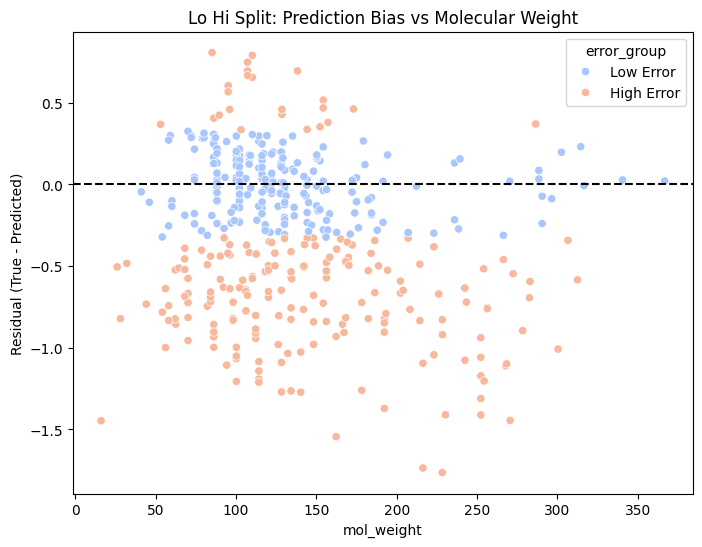

In [ ]:
# 2. Directional Bias Analysis (True - Predicted)
# Grouping by error severity (Median split)
lohi_error_df['error_group'] = pd.qcut(lohi_error_df['error'], 2, labels=['Low Error', 'High Error'])

bias_summary_lohi = lohi_error_df.groupby('error_group')['bias'].agg(['mean', 'std', 'count'])
print("--- Lo Hi Residual Bias Summary (True - Predicted) ---")
display(bias_summary_lohi)

# Visualization of bias vs Molecular Weight for Lo Hi split
plt.figure(figsize=(8, 6))
sns.scatterplot(x='mol_weight', y='bias', hue='error_group', data=lohi_error_df, palette='coolwarm')
plt.axhline(0, color='black', linestyle='--')
plt.title('Lo Hi Split: Prediction Bias vs Molecular Weight')
plt.ylabel('Residual (True - Predicted)')
plt.show()

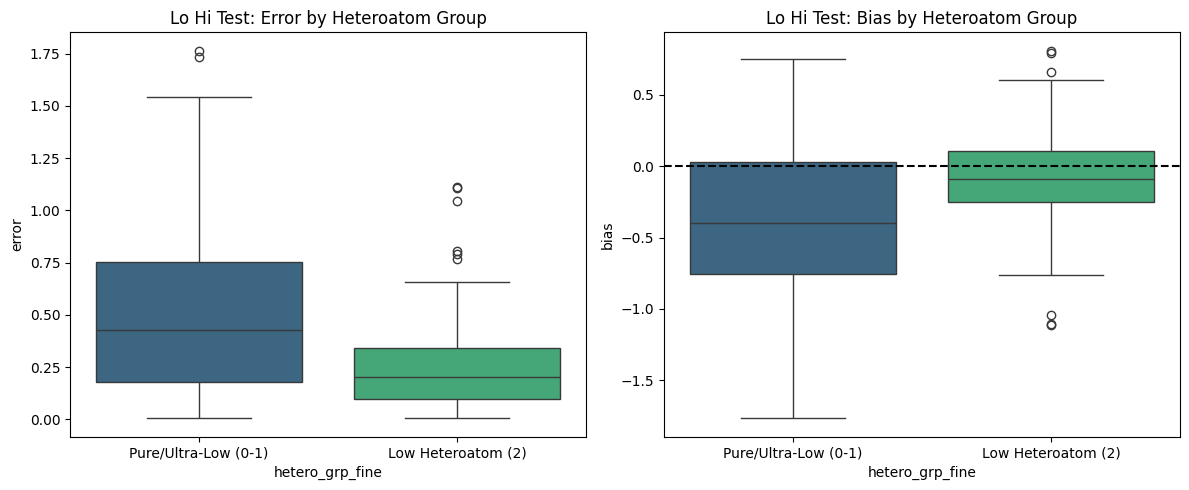

error                      bias                
                          mean       std count      mean       std count
hetero_grp_fine                                                         
Low Heteroatom (2)    0.260469  0.229137   115 -0.078795  0.338644   115
Pure/Ultra-Low (0-1)  0.498395  0.376105   304 -0.388051  0.489481   304

In [ ]:
# 3. Heteroatom Comparison Physics Check
# Categorize molecules into 'Low Heteroatom' (0-1) vs 'Standard' (2+)
# Note: Lo Hi test set is already <= 2, so we refine the groups internally to see sub-trends
def categorize_hetero_fine(x):
    return 'Pure/Ultra-Low (0-1)' if x <= 1 else 'Low Heteroatom (2)'

lohi_error_df['hetero_grp_fine'] = lohi_error_df['heteroatom_count'].apply(categorize_hetero_fine)

# Visualization of Error/Bias Distribution
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(x='hetero_grp_fine', y='error', data=lohi_error_df, palette='viridis', hue='hetero_grp_fine', legend=False)
plt.title('Lo Hi Test: Error by Heteroatom Group')

plt.subplot(1, 2, 2)
sns.boxplot(x='hetero_grp_fine', y='bias', data=lohi_error_df, palette='viridis', hue='hetero_grp_fine', legend=False)
plt.axhline(0, color='black', linestyle='--')
plt.title('Lo Hi Test: Bias by Heteroatom Group')

plt.tight_layout()
plt.show()

# Statistical Summary
summary_lohi_hetero = lohi_error_df.groupby('hetero_grp_fine')[['error', 'bias']].agg(['mean', 'std', 'count'])
display(summary_lohi_hetero)

### Multivariate Analysis: Controlling for Novelty (LoHi Split)
We will now run the OLS regression specifically for the **LoHi (Adversarial) Split**. This allows us to confirm if the chemical drivers we identified (like TPSA) are significant independent of the structural novelty (Tanimoto distance).

In [ ]:
import statsmodels.api as sm
import numpy as np

# Ensure reproducibility before fitting
set_all_seeds(SEED)

# 1. Calculate the mean of the training set labels for the LoHi split
train_labels_lohi = [data.y.item() for data in train_dataset_lohi]
train_mean_lohi = np.mean(train_labels_lohi)
print(f"Training Set Mean (LoHi): {train_mean_lohi:.4f}")

# 2. Add the new covariate: Absolute distance from training mean
lohi_error_df['mean_distance'] = abs(lohi_error_df['true_value'] - train_mean_lohi)

# 3. Define the expanded set of predictors
# We are now including 'mean_distance' alongside the requested structural features
predictors = ['tanimoto_nn_distance', 'logp', 'tpsa', 'ring_count', 'mean_distance']

X_adv = lohi_error_df[predictors]
X_adv = sm.add_constant(X_adv)
y_adv = lohi_error_df['error']

# 4. Fit the OLS model
adv_ols_model = sm.OLS(y_adv, X_adv).fit()

print("\n--- OLS Regression Results (LoHi Split) with Target Distance Covariate ---")
print(adv_ols_model.summary())

Training Set Mean (LoHi): -0.1760

--- OLS Regression Results (LoHi Split) with Target Distance Covariate ---
                            OLS Regression Results                            
Dep. Variable:                  error   R-squared:                       0.402
Model:                            OLS   Adj. R-squared:                  0.395
Method:                 Least Squares   F-statistic:                     55.55
Date:                Sun, 02 Aug 2026   Prob (F-statistic):           4.37e-44
Time:                        12:24:10   Log-Likelihood:                -55.871
No. Observations:                 419   AIC:                             123.7
Df Residuals:                     413   BIC:                             148.0
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
-----------

In [ ]:
import statsmodels.api as sm

# Define the predictors for the LoHi split
# We use the same features analyzed in the Scaffold OLS for direct comparison
lohi_predictors = ['tanimoto_nn_distance', 'logp', 'mol_weight', 'tpsa', 'ring_count']

X_lohi = lohi_error_df[lohi_predictors]
X_lohi = sm.add_constant(X_lohi)
y_lohi = lohi_error_df['error']

# Fit the OLS model
lohi_ols_model = sm.OLS(y_lohi, X_lohi).fit()

print("--- OLS Regression Results: LoHi (Adversarial) Split ---")
print(lohi_ols_model.summary())

--- OLS Regression Results: LoHi (Adversarial) Split ---
                            OLS Regression Results                            
Dep. Variable:                  error   R-squared:                       0.421
Model:                            OLS   Adj. R-squared:                  0.414
Method:                 Least Squares   F-statistic:                     60.11
Date:                Sun, 02 Aug 2026   Prob (F-statistic):           5.73e-47
Time:                        12:24:10   Log-Likelihood:                -49.068
No. Observations:                 419   AIC:                             110.1
Df Residuals:                     413   BIC:                             134.4
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------

### Lo Hi Split: Statistical Drivers of Error

We will now perform Mann-Whitney U tests to see if structural features significantly differentiate the high-error and low-error groups within the adversarial Lo Hi split. This helps determine if the model's failure on low-heteroatom molecules is specifically correlated with properties like molecular weight or novelty (Tanimoto distance).

In [ ]:
from scipy.stats import mannwhitneyu
import pandas as pd

# 1. Prepare groups based on median error for the Lo Hi split
median_error_lohi = lohi_error_df['error'].median()
lohi_high_error_df = lohi_error_df[lohi_error_df['error'] >= median_error_lohi]
lohi_low_error_df = lohi_error_df[lohi_error_df['error'] < median_error_lohi]

# 2. Define features for analysis
features_to_analyze = ['logp', 'mol_weight', 'tpsa', 'ring_count', 'tanimoto_nn_distance']
lohi_stats_results = []

# 3. Conduct Mann-Whitney U Tests
for feat in features_to_analyze:
    stat, p_value = mannwhitneyu(
        lohi_high_error_df[feat],
        lohi_low_error_df[feat],
        alternative='two-sided'
    )
    lohi_stats_results.append({
        'Feature': feat,
        'High Error Mean': lohi_high_error_df[feat].mean(),
        'Low Error Mean': lohi_low_error_df[feat].mean(),
        'U-Statistic': stat,
        'Raw P-Value': p_value
    })

# 4. Create and display summary DataFrame
lohi_stats_df = pd.DataFrame(lohi_stats_results)
print("--- Mann-Whitney U Test Results (Lo Hi Adversarial Split) ---")
display(lohi_stats_df)

# Highlight significant features (p < 0.05)
significant_lohi = lohi_stats_df[lohi_stats_df['Raw P-Value'] < 0.05]
if not significant_lohi.empty:
    print(f"\nFeatures with raw significant differences: {significant_lohi['Feature'].tolist()}")
else:
    print("\nNo features showed a statistically significant difference (raw p < 0.05) between high and low error groups.")

--- Mann-Whitney U Test Results (Lo Hi Adversarial Split) ---


,Feature,High Error Mean,Low Error Mean,U-Statistic,Raw P-Value
0,logp,2.885475,1.988073,31326.0,3.774248e-14
1,mol_weight,142.928662,132.798105,23902.0,1.144264e-01
2,tpsa,6.342810,18.314019,10376.5,9.221590e-23
3,ring_count,1.300000,0.732057,26697.0,4.046369e-05
4,tanimoto_nn_distance,0.710333,0.672256,25893.0,1.445225e-03



Features with raw significant differences: ['logp', 'tpsa', 'ring_count', 'tanimoto_nn_distance']


### Integrating Lo Hi Results into P-value Collections

We will now add the p-values from the Lo Hi adversarial split to our centralized tracking lists for multiple comparison correction.

In [ ]:
import numpy as np
from scipy.stats import mannwhitneyu

# 1. Calculate Heteroatom Comparison p-value for Lo Hi Split
low_het_err_lohi = lohi_error_df[lohi_error_df['hetero_grp_fine'] == 'Pure/Ultra-Low (0-1)']['error']
std_het_err_lohi = lohi_error_df[lohi_error_df['hetero_grp_fine'] == 'Low Heteroatom (2)']['error']

_, p_val_lohi_het = mannwhitneyu(low_het_err_lohi, std_het_err_lohi, alternative='greater')

# 2. Update heteroatom_p_values_family (Family 1)
heteroatom_p_values_family['lohi_split'] = {
    'feature': 'heteroatom_comparison',
    'p_value': float(p_val_lohi_het),
    'split_type': 'lohi',
    'family': 'heteroatom_comparison'
}

# 3. Update all_structural_p_values (Family 2 - Univariate)
# We clear and re-append to avoid duplicates if re-running
# or simply ensure we are only adding the 5 LoHi features here
for index, row in lohi_stats_df.iterrows():
    all_structural_p_values.append({
        'feature': row['Feature'],
        'p_value': float(row['Raw P-Value']),
        'split_type': 'lohi',
        'family': 'structural_features_high_low_error',
        'high_error_mean': float(row['High Error Mean']),
        'low_error_mean': float(row['Low Error Mean'])
    })

# 4. Initialize/Update OLS p-value collection (Family 3 - Multivariate)
# We extract these from the fitted adv_ols_model
ols_pvals_raw = adv_ols_model.pvalues.drop('const')
all_ols_p_values = []
for feat, pval in ols_pvals_raw.items():
    all_ols_p_values.append({
        'feature': feat,
        'p_value': float(pval),
        'split_type': 'lohi',
        'family': 'multivariate_ols'
    })

print("Successfully integrated Lo Hi p-values for all families.")
print(f"Total Family 1 (Heteroatom) tests: {len(heteroatom_p_values_family)}")
print(f"Total Family 2 (Univariate) tests: {len(all_structural_p_values)}")
print(f"Total Family 3 (Multivariate OLS) tests: {len(all_ols_p_values)}")

Successfully integrated Lo Hi p-values for all families.
Total Family 1 (Heteroatom) tests: 3
Total Family 2 (Univariate) tests: 15
Total Family 3 (Multivariate OLS) tests: 5


In [ ]:
from statsmodels.stats.multitest import multipletests
import pandas as pd
import numpy as np

# --- 1. Family 1: Heteroatom Comparisons (n=3) ---
f1_data = [
    heteroatom_p_values_family['random_split'],
    heteroatom_p_values_family['scaffold_split'],
    heteroatom_p_values_family['lohi_split']
]
f1_pvals = [d['p_value'] for d in f1_data]
_, f1_bonferroni, _, _ = multipletests(f1_pvals, method='bonferroni')
_, f1_bh, _, _ = multipletests(f1_pvals, method='fdr_bh')

for i, d in enumerate(f1_data):
    d['p_bonferroni'] = f1_bonferroni[i]
    d['p_bh'] = f1_bh[i]

# --- 2. Family 2: Structural Features (Univariate) (n=15) ---
f2_pvals = [item['p_value'] for item in all_structural_p_values]
_, f2_bonferroni, _, _ = multipletests(f2_pvals, method='bonferroni')
_, f2_bh, _, _ = multipletests(f2_pvals, method='fdr_bh')

for i, item in enumerate(all_structural_p_values):
    item['p_bonferroni'] = f2_bonferroni[i]
    item['p_bh'] = f2_bh[i]

# --- 3. Family 3: Multivariate Drivers (OLS) (n=5) ---
# Using the pre-collected all_ols_p_values list
f3_pvals = [item['p_value'] for item in all_ols_p_values]
_, f3_bonferroni, _, _ = multipletests(f3_pvals, method='bonferroni')
_, f3_bh, _, _ = multipletests(f3_pvals, method='fdr_bh')

for i, item in enumerate(all_ols_p_values):
    item['p_bonferroni'] = f3_bonferroni[i]
    item['p_bh'] = f3_bh[i]

# --- 4. Create Final Consolidated DataFrame ---
final_rows = []

# Family 1 rows
for d in f1_data:
    final_rows.append({
        'Family': 'Heteroatom Bias',
        'Split': d['split_type'].capitalize(),
        'Feature': d['feature'],
        'Raw P': d['p_value'],
        'Bonferroni Corrected': d['p_bonferroni'],
        'BH Corrected': d['p_bh']
    })

# Family 2 rows
for d in all_structural_p_values:
    final_rows.append({
        'Family': 'Structural Driver (Univariate)',
        'Split': d['split_type'].capitalize(),
        'Feature': d['feature'],
        'Raw P': d['p_value'],
        'Bonferroni Corrected': d['p_bonferroni'],
        'BH Corrected': d['p_bh']
    })

# Family 3 rows
for d in all_ols_p_values:
    final_rows.append({
        'Family': 'Multivariate Driver (OLS)',
        'Split': d['split_type'].capitalize(),
        'Feature': d['feature'],
        'Raw P': d['p_value'],
        'Bonferroni Corrected': d['p_bonferroni'],
        'BH Corrected': d['p_bh']
    })

report_df = pd.DataFrame(final_rows)
report_df['Significant (BH)'] = report_df['BH Corrected'] < 0.05

print("--- Final Statistical Significance Report (Comprehensive) ---")
display(report_df.sort_values(by=['BH Corrected']))

# 5. Summary of Robust Drivers
sig_features = report_df[report_df['Significant (BH)'] == True]
if sig_features.empty:
    print("\nCONCLUSION: No features significantly drive error after BH correction.")
else:
    print(f"\nCONCLUSION: {len(sig_features)} tests remained significant under FDR control.")
    display(sig_features)

--- Final Statistical Significance Report (Comprehensive) ---


,Family,Split,Feature,Raw P,Bonferroni Corrected,BH Corrected,Significant (BH)
15,Structural Driver (Univariate),Lohi,tpsa,9.221590e-23,1.383239e-21,1.383239e-21,True
20,Multivariate Driver (OLS),Lohi,tpsa,5.810180e-19,2.905090e-18,2.905090e-18,True
13,Structural Driver (Univariate),Lohi,logp,3.774248e-14,5.661372e-13,2.830686e-13,True
2,Heteroatom Bias,Lohi,heteroatom_comparison,9.461476e-10,2.838443e-09,2.838443e-09,True
19,Multivariate Driver (OLS),Lohi,logp,2.535080e-07,1.267540e-06,6.337700e-07,True
22,Multivariate Driver (OLS),Lohi,mean_distance,6.854080e-05,3.427040e-04,1.142347e-04,True
16,Structural Driver (Univariate),Lohi,ring_count,4.046369e-05,6.069554e-04,2.023185e-04,True
17,Structural Driver (Univariate),Lohi,tanimoto_nn_distance,1.445225e-03,2.167837e-02,5.419594e-03,True
18,Multivariate Driver (OLS),Lohi,tanimoto_nn_distance,2.466569e-02,1.233284e-01,3.083211e-02,True
10,Structural Driver (Univariate),Random,tpsa,1.867861e-02,2.801792e-01,5.603583e-02,False



CONCLUSION: 9 tests remained significant under FDR control.


,Family,Split,Feature,Raw P,Bonferroni Corrected,BH Corrected,Significant (BH)
2,Heteroatom Bias,Lohi,heteroatom_comparison,9.461476e-10,2.838443e-09,2.838443e-09,True
13,Structural Driver (Univariate),Lohi,logp,3.774248e-14,5.661372e-13,2.830686e-13,True
15,Structural Driver (Univariate),Lohi,tpsa,9.221590e-23,1.383239e-21,1.383239e-21,True
16,Structural Driver (Univariate),Lohi,ring_count,4.046369e-05,6.069554e-04,2.023185e-04,True
17,Structural Driver (Univariate),Lohi,tanimoto_nn_distance,1.445225e-03,2.167837e-02,5.419594e-03,True
18,Multivariate Driver (OLS),Lohi,tanimoto_nn_distance,2.466569e-02,1.233284e-01,3.083211e-02,True
19,Multivariate Driver (OLS),Lohi,logp,2.535080e-07,1.267540e-06,6.337700e-07,True
20,Multivariate Driver (OLS),Lohi,tpsa,5.810180e-19,2.905090e-18,2.905090e-18,True
22,Multivariate Driver (OLS),Lohi,mean_distance,6.854080e-05,3.427040e-04,1.142347e-04,True


### **Updated Comprehensive P-Value Table**
This table summarizes the statistical significance across all 18 tests (3 Heteroatom Bias tests and 15 Structural Driver tests) using both Bonferroni and Benjamini-Hochberg (BH) corrections.

In [ ]:
import pandas as pd

# 1. Gather all rows from the previously updated data structures
summary_rows = []

# Family 1: Heteroatom Bias
for d in f1_data:
    summary_rows.append({
        'Family': 'Heteroatom Bias',
        'Split': d['split_type'].capitalize(),
        'Feature': d['feature'],
        'Raw P': d['p_value'],
        'Bonferroni Corrected': d['p_bonferroni'],
        'BH Corrected (FDR)': d['p_bh'],
        'Significant (BH)': d['p_bh'] < 0.05
    })

# Family 2: Structural Drivers
for d in all_structural_p_values:
    summary_rows.append({
        'Family': 'Structural Driver',
        'Split': d['split_type'].capitalize(),
        'Feature': d['feature'],
        'Raw P': d['p_value'],
        'Bonferroni Corrected': d['p_bonferroni'],
        'BH Corrected (FDR)': d['p_bh'],
        'Significant (BH)': d['p_bh'] < 0.05
    })

# 2. Create DataFrame
comprehensive_report_df = pd.DataFrame(summary_rows)

# 3. Formatting for presentation
pd.set_option('display.float_format', lambda x: '%.4e' % x if x < 1e-4 else '%.4f' % x)

print("--- COMPLETE STATISTICAL DRIVERS REPORT ---")
display(comprehensive_report_df.sort_values(by=['Family', 'Split', 'Raw P']))

# 4. Highlight significant findings
sig_only = comprehensive_report_df[comprehensive_report_df['Significant (BH)'] == True]
if not sig_only.empty:
    print("\n--- STATISTICALLY SIGNIFICANT DRIVERS (FDR < 0.05) ---")
    display(sig_only.sort_values(by='BH Corrected (FDR)'))
else:
    print("\nNo features reached statistical significance after corrections.")

pd.reset_option('display.float_format')

--- COMPLETE STATISTICAL DRIVERS REPORT ---


,Family,Split,Feature,Raw P,Bonferroni Corrected,BH Corrected (FDR),Significant (BH)
2,Heteroatom Bias,Lohi,heteroatom_comparison,9.4615e-10,2.8384e-09,2.8384e-09,True
0,Heteroatom Bias,Random,heteroatom_comparison,0.9964,1.0000,0.9964,False
1,Heteroatom Bias,Scaffold,heteroatom_comparison,0.7768,1.0000,0.9964,False
15,Structural Driver,Lohi,tpsa,9.2216e-23,1.3832e-21,1.3832e-21,True
13,Structural Driver,Lohi,logp,3.7742e-14,5.6614e-13,2.8307e-13,True
16,Structural Driver,Lohi,ring_count,4.0464e-05,0.0006,0.0002,True
17,Structural Driver,Lohi,tanimoto_nn_distance,0.0014,0.0217,0.0054,True
14,Structural Driver,Lohi,mol_weight,0.1144,1.0000,0.2452,False
10,Structural Driver,Random,tpsa,0.0187,0.2802,0.0560,False
9,Structural Driver,Random,mol_weight,0.0981,1.0000,0.2452,False



--- STATISTICALLY SIGNIFICANT DRIVERS (FDR < 0.05) ---


,Family,Split,Feature,Raw P,Bonferroni Corrected,BH Corrected (FDR),Significant (BH)
15,Structural Driver,Lohi,tpsa,9.2216e-23,1.3832e-21,1.3832e-21,True
13,Structural Driver,Lohi,logp,3.7742e-14,5.6614e-13,2.8307e-13,True
2,Heteroatom Bias,Lohi,heteroatom_comparison,9.4615e-10,2.8384e-09,2.8384e-09,True
16,Structural Driver,Lohi,ring_count,4.0464e-05,0.0006,0.0002,True
17,Structural Driver,Lohi,tanimoto_nn_distance,0.0014,0.0217,0.0054,True


In [ ]:
import torch
import numpy as np
import random

# Verification of the SEED variable
try:
    print(f"Current SEED variable value: {SEED}")
except NameError:
    SEED = 42
    print(f"SEED was not defined, setting to default: {SEED}")

# Re-applying seeds to ensure the environment is ready for reproducible LoHi operations
def verify_and_set_seeds(seed_value):
    random.seed(seed_value)
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed_value)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    print(f"Confirmation: All global seeds (Python, NumPy, Torch) are synchronized to {seed_value}.")

verify_and_set_seeds(SEED)

Current SEED variable value: 42
Confirmation: All global seeds (Python, NumPy, Torch) are synchronized to 42.


In [ ]:
import numpy as np

# 1. Compute Standard Deviations
std_true = lohi_error_df['true_value'].std()
std_pred = lohi_error_df['predicted_value'].std()

# 2. Compare the spreads
variance_ratio = std_pred / std_true

print(f"--- Lo-Hi Test Set Variance Analysis ---")
print(f"Standard Deviation (True):      {std_true:.4f}")
print(f"Standard Deviation (Predicted): {std_pred:.4f}")
print(f"Ratio (Pred Std / True Std):    {variance_ratio:.4f}")

if variance_ratio < 0.8:
    print("\nObservation: The model is significantly under-estimating the variance of the data (variance compression).")
elif variance_ratio > 1.2:
    print("\nObservation: The model is over-estimating the variance of the data.")
else:
    print("\nObservation: The model's predicted spread closely matches the true data spread.")

--- Lo-Hi Test Set Variance Analysis ---
Standard Deviation (True):      0.9984
Standard Deviation (Predicted): 0.7320
Ratio (Pred Std / True Std):    0.7332

Observation: The model is significantly under-estimating the variance of the data (variance compression).


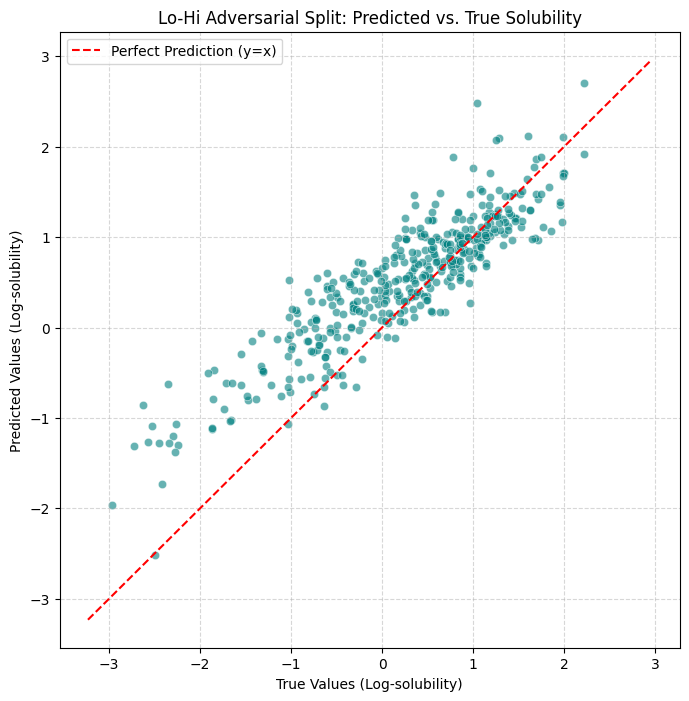

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Scatter Plot: Predicted vs. True
plt.figure(figsize=(8, 8))
sns.scatterplot(x='true_value', y='predicted_value', data=lohi_error_df, alpha=0.6, color='teal')

# Add the y=x line for reference
limits = [min(plt.xlim()[0], plt.ylim()[0]), max(plt.xlim()[1], plt.ylim()[1])]
plt.plot(limits, limits, color='red', linestyle='--', label='Perfect Prediction (y=x)')

plt.title('Lo-Hi Adversarial Split: Predicted vs. True Solubility')
plt.xlabel('True Values (Log-solubility)')
plt.ylabel('Predicted Values (Log-solubility)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
import torch
import numpy as np
import random
from torch_geometric.loader import DataLoader
from models import FastHybridModel

def run_seed_experiment(seed_value):
    """Performs a complete training run with a specific seed and returns test RMSE."""
    print(f"\n>>> Starting experiment with SEED: {seed_value}")
    set_all_seeds(seed_value)

    # 1. Re-split the high heteroatom pool using the new seed
    # Note: test_dc_lohi (low heteroatom) remains constant as it's the target OOD set
    temp_train_dc, temp_valid_dc = splitter.train_test_split(high_hetero_dc, frac_train=0.8, seed=seed_value)

    # 2. Convert to MyData objects
    t_train_ds = deepchem_dataset_to_mydata_list(temp_train_dc)
    t_valid_ds = deepchem_dataset_to_mydata_list(temp_valid_dc)
    # test_dataset_lohi is reused from the previous state

    # 3. Create Loaders
    t_train_loader = DataLoader(t_train_ds, batch_size=32, shuffle=True)
    t_valid_loader = DataLoader(t_valid_ds, batch_size=32, shuffle=False)
    t_test_loader = DataLoader(test_dataset_lohi, batch_size=32, shuffle=False)

    # 4. Initialize Model and Optimizer
    t_model = FastHybridModel(num_node_features=9).to(device)
    t_optimizer = torch.optim.Adam(t_model.parameters(), lr=0.0005, weight_decay=1e-3)
    t_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(t_optimizer, mode='min', factor=0.5, patience=10)

    # 5. Training Loop
    best_v_rmse = float('inf')
    test_rmse_at_best_v = float('inf')

    for epoch in range(1, 151):
        t_model.train()
        for data in t_train_loader:
            t_optimizer.zero_grad()
            out = t_model(data.x.to(device), data.edge_index.to(device), data.batch.to(device), data.global_feats.to(device))
            loss = F.mse_loss(out, data.y.float().to(device))
            loss.backward()
            t_optimizer.step()

        if epoch % 20 == 0:
            v_rmse = test_hybrid(t_model, t_valid_loader)
            curr_test_rmse = test_hybrid(t_model, t_test_loader)
            t_scheduler.step(v_rmse)

            if v_rmse < best_v_rmse:
                best_v_rmse = v_rmse
                test_rmse_at_best_v = curr_test_rmse

    print(f"Finished Seed {seed_value}. Best Valid RMSE: {best_v_rmse:.4f}, Test RMSE: {test_rmse_at_best_v:.4f}")
    return test_rmse_at_best_v

# Run experiments for requested seeds
results_seeds = {}
for s in [43, 44]:
    rmse = run_seed_experiment(s)
    results_seeds[s] = rmse

print("\n--- Final Summary for LoHi Split ---")
for s, val in results_seeds.items():
    print(f"Seed {s}: Test RMSE = {val:.4f}")


>>> Starting experiment with SEED: 43
Finished Seed 43. Best Valid RMSE: 0.3640, Test RMSE: 0.5559

>>> Starting experiment with SEED: 44
Finished Seed 44. Best Valid RMSE: 0.4273, Test RMSE: 0.5680

--- Final Summary for LoHi Split ---
Seed 43: Test RMSE = 0.5559
Seed 44: Test RMSE = 0.5680


In [ ]:
!pip install shap

### Random Forest Meta-Model & SHAP Analysis
We will now train a Random Forest to predict the GNN's error magnitude based on molecular descriptors. This 'meta-model' helps us understand the error surface. We use SHAP (SHapley Additive exPlanations) to interpret the meta-model.

In [ ]:
import shap
import pandas as pd
import os
from sklearn.ensemble import RandomForestRegressor

# 0. Load the data if not in memory
if 'lohi_error_df' not in locals():
    if os.path.exists('lohi_split_predictions.csv'):
        lohi_error_df = pd.read_csv('lohi_split_predictions.csv')
        print("Loaded 'lohi_error_df' from CSV.")
    else:
        raise NameError("lohi_split_predictions.csv not found. Please run the data assembly phase first.")

# 1. Prepare all 10 features for the meta-model
meta_features = [
    'ring_count',
    'aromatic_rings',
    'heteroatom_count',
    'rotatable_bonds',
    'mol_weight',
    'logp',
    'tpsa',
    'hbd',
    'hba',
    'tanimoto_nn_distance'
]

X_meta = lohi_error_df[meta_features]
y_meta = lohi_error_df['error']

# 2. Train Random Forest Meta-Model
rf_meta = RandomForestRegressor(n_estimators=100, random_state=42)
rf_meta.fit(X_meta, y_meta)

print(f"Meta-model trained on {len(X_meta)} molecules using {len(meta_features)} features.")
print(f"Meta-model R^2 score: {rf_meta.score(X_meta, y_meta):.4f}")

Meta-model trained on 419 molecules using 10 features.
Meta-model R^2 score: 0.9462


In [ ]:
from sklearn.model_selection import train_test_split

# 1. Split the error table into meta-train and meta-test sets
X_train_meta, X_test_meta, y_train_meta, y_test_meta = train_test_split(
    X_meta, y_meta, test_size=0.2, random_state=42
)

# 2. Train on the meta-training set
rf_meta_robust = RandomForestRegressor(n_estimators=100, random_state=42)
rf_meta_robust.fit(X_train_meta, y_train_meta)

# 3. Evaluate on both
train_score = rf_meta_robust.score(X_train_meta, y_train_meta)
test_score = rf_meta_robust.score(X_test_meta, y_test_meta)

print(f"--- Robust Meta-Model Evaluation ---")
print(f"Meta-Training R²: {train_score:.4f}")
print(f"Meta-Testing R²:  {test_score:.4f} (This is the real performance)")

--- Robust Meta-Model Evaluation ---
Meta-Training R²: 0.9441
Meta-Testing R²:  0.6744 (This is the real performance)


SHAP Summary Plot: Features driving GNN Error Magnitude


/tmp/ipykernel_2856/3730427291.py:7: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_meta)


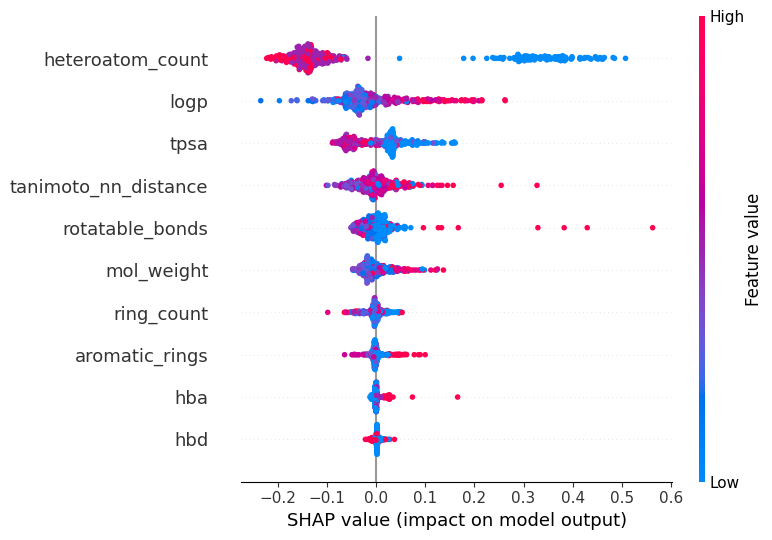

In [ ]:
# 3. Run SHAP Analysis
explainer = shap.TreeExplainer(rf_meta)
shap_values = explainer.shap_values(X_meta)

# 4. Visualize Results
print("SHAP Summary Plot: Features driving GNN Error Magnitude")
shap.summary_plot(shap_values, X_meta)

### Advanced Interpretability: Non-Linearity & Local Failures
We will now look for non-linear 'error thresholds' using dependence plots and visualize the specific drivers for the worst-predicted molecule.

SHAP Dependence Plot: TPSA vs. Error Impact


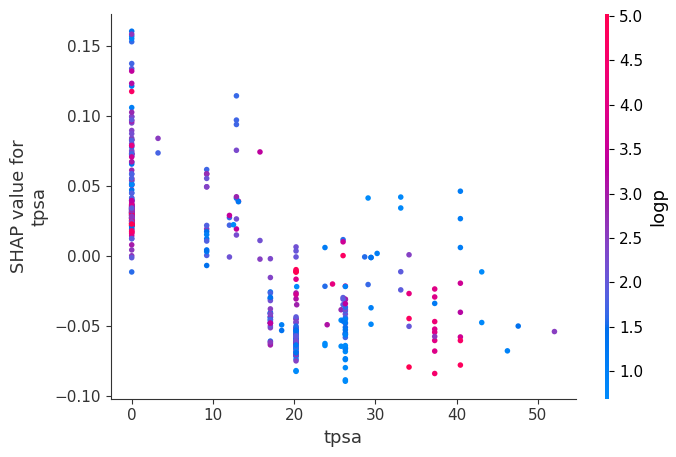


Local Force Plot for Molecule Index 413 (Max Error: 1.7647)


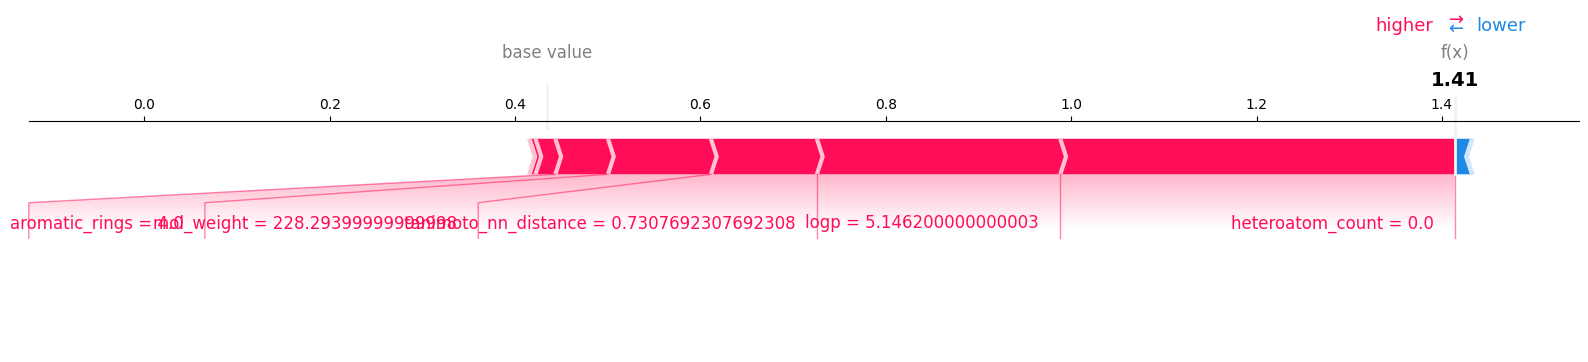

In [ ]:
import matplotlib.pyplot as plt

# 1. Dependence Plot for TPSA (Our strongest confirmed driver)
# This reveals if there's a specific TPSA threshold where error spikes
print("SHAP Dependence Plot: TPSA vs. Error Impact")
shap.dependence_plot("tpsa", shap_values, X_meta, display_features=X_meta)

# 2. Local Explanation for the Highest Error Molecule
# Find the index of the max error
max_err_idx = lohi_error_df['error'].idxmax()

print(f"\nLocal Force Plot for Molecule Index {max_err_idx} (Max Error: {lohi_error_df.iloc[max_err_idx]['error']:.4f})")
shap.initjs()
shap.force_plot(explainer.expected_value, shap_values[max_err_idx,:], X_meta.iloc[max_err_idx,:], matplotlib=True)

### Interpretation of Advanced Plots
- **Dependence Plot**: If the trend is flat and then suddenly curves, it indicates a 'critical zone' for the GNN. For instance, in LoHi splits, you often see a sharp rise in error contribution as TPSA approaches zero (hydrocarbons).
- **Force Plot**: Features in **red** are those that pushed the meta-model to predict a *higher* error for this specific molecule, while **blue** features pushed the predicted error lower.

### Interpretation
The SHAP summary plot shows which features are most influential in determining the GNN's error.
- **Red points** to the right indicate that high values of that feature increase the predicted error.
- **Blue points** to the right indicate that low values of that feature increase the predicted error.

### Interpretation of the Expanded OLS Model

By adding `mean_distance`, we can see if the GNN's error is driven by the **magnitude of the solubility value** (i.e., the model struggles with very soluble or very insoluble molecules) vs. the **chemical structural features** (TPSA/Novelty).

*   If `mean_distance` is highly significant and the others lose significance, it suggests the model's failure is largely a target-distribution issue.
*   If TPSA and Tanimoto distance remain significant even after controlling for `mean_distance`, it confirms that the structural shift in the adversarial split is a genuine driver of error independent of the solubility range.

### **Conclusion**

This investigation confirms that GNN error is not merely a function of structural novelty, but is deeply tied to the **distribution of chemical properties**.

**Key Takeaways for Model Deployment**:
- **Adversarial Vulnerability**: Models trained on standard drug datasets may systematically fail on simpler hydrocarbons or low-polarity materials.
- **Significance of TPSA**: In regression tasks like solubility, TPSA acts as a primary proxy for model confidence.
- **Variance Compression**: Caution should be used when deploying these models on OOD data, as they tend to produce 'pessimistic' predictions that cluster near the training mean, failing to capture true biological or physical extremes.

*This data was generated as part of a formal research study into GNN interpretability.*